In [27]:
import pandas as pd

def get_current_bonds(file_iter, N_patches, patch_molecule_map=None, pairs=False):
    current_bonds = set() # track current bonded pairs in this frame to compare with bonded_pairs dict
    clusters = pd.read_csv(file_iter, delimiter='\s+', header=None, nrows=N_patches, usecols=[0,1,5,6], names=['id', 'mol', 'patch_coord', 'patch_cluster'])
    bonded_clusters = clusters.loc[clusters['patch_coord'] > 0].copy() # filter only consider bonds with at least 1 patch (patch_coord is in column 5)
    bonded_clusters.sort_values(by='patch_cluster', inplace=True) # sort by patch_cluster (get bonded pairs) (patch_cluster is in column 6)
    bonded_clusters.reset_index(drop=True, inplace=True)

    arr = bonded_clusters.to_numpy()

    with open('temp.txt', "w") as f:
        for id in np.unique(clusters['id']):
            f.write(str(id) + "\n")

    for i in range(len(arr)-1):
        id1, id2 = int(arr[i, 0]), int(arr[i+1, 0]) # get ids of current and next cluster
        if int(arr[i, 2]) == int(arr[i+1, 2]): # if same patch_cluster, they are bonded
            if pairs:
                patch_molecule_map[id1] = int(arr[i, 1]) # map patch id to molecule id
                patch_molecule_map[id2] = int(arr[i+1, 1]) # map patch id to molecule id
                
                ids = (id1, id2) if id1 < id2 else (id2, id1) # order ids to avoid duplicates
                current_bonds.add(ids) # add to current bonds set
            else:
                current_bonds.add(id1) # add to current bonds set
                current_bonds.add(id2) # add to current bonds set
    
    return current_bonds

<>:5: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:5: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_1588283/1213789484.py:5: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  clusters = pd.read_csv(file_iter, delimiter='\s+', header=None, nrows=N_patches, usecols=[0,1,5,6], names=['id', 'mol', 'patch_coord', 'patch_cluster'])


In [28]:
# given an association state s, we can convert it to a binary representation
def association_to_s(state):
    s = 0
    for i, val in enumerate(state):
        if val == 1:
            s += 2**i
    return s

In [29]:
def count_s(bonded_pairs, patch_molecule_map, N_a=7, N_b=31, M=5, N_chains=800):
    bonded_patches = set() # track patches that are currently bonded
    molecule_ids = set() # track unique molecule ids that are currently bonded
    counts = {}

    for ids in bonded_pairs.keys():
        bonded_patches.add(ids[0])
        bonded_patches.add(ids[1])

        molecule_ids.add(patch_molecule_map[ids[0]])
        molecule_ids.add(patch_molecule_map[ids[1]])

    for mol_id in molecule_ids:
        state = [0] * N_a
        patches = [patch_id for patch_id, m_id in patch_molecule_map.items() if m_id == mol_id]

        for patch_id in patches:
            if patch_id in bonded_patches:
                state_id = patch_id - (N_b + N_a) * (mol_id - 1) - N_b
                state[state_id - 1] = 1

        s = association_to_s(state)
        counts[s] = counts.get(s, 0) + 1

    counts[0] = N_chains - len(molecule_ids)  # count unbonded chains (s=0)

    return counts

## $\nu^s$ algorithm with different $r_{\text{on}}, r_{\text{off}}$

Getting the number density of chains with a specific association state $s$, we can read a few (not too many, it will be a time series just to make sure it isn't too fluctuating) frames and return the density, so we also need the dimensions of the box. We can then compare it to the detailed balance assumption/result in equation 16 of Indei & Takimoto.


In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

"""
Process number density of association state s from clustering data file. Each frame of the file contains the following sections:
- "ITEM: TIMESTEP" followed by the timestep on the next line
- "ITEM: NUMBER OF ATOMS" followed by the number of entries on the next line
- "ITEM: ATOMS" followed by the data lines for each entry, with 7 values per line: id, mol, x, y, z, patch_coord, patch_cluster

Args:
    - filename_on: path to the clustering data file for determining bond creation
    - filename_off: path to the clustering data file for determining bond destruction
    - frames: number of frames to read, starting from the beginning
Returns:
    - count_time_series: dict with (time, counts) pairs where counts is dict with all valid s and their counts at that time
"""
def process_buffered_s_counts(filename_on, filename_off, frames=1, timestep=0.002):
    # init empty bond lifetime list
    bond_lifetimes = []
    # init empty bonded pair dict. lookup by (id1, id2) where id1 < id2 to avoid duplicates. value is start_time of the bond
    bonded_pairs = {}
    patch_molecule_map = {} # map patch id to molecule id

    count_time_series = {}

    N_patches = 0
    time = 0
    read_frames = 0
    with open(filename_on, 'r') as f_on:
        with open(filename_off, 'r') as f_off:
            while True:
                # stop reading BOTH if either file is done
                # reading f_on, only creating bonds
                line = f_on.readline()
                if not line:
                    break
                if line.startswith("ITEM: TIMESTEP"): # timestep is on next line
                    time = float(f_on.readline().strip()) * timestep # convert to time units
                    # print(f"Processing timestep: {time / timestep:.0f} (time units: {time})")
                elif line.startswith("ITEM: NUMBER OF ATOMS"): # number of entries is on next line
                    N_patches = int(f_on.readline().strip())
                elif line.startswith("ITEM: ATOMS"): # data starts on next line
                    current_bonds = get_current_bonds(f_on, N_patches, patch_molecule_map, pairs=True)
                    
                    for ids in current_bonds:
                        if ids not in bonded_pairs: # if new bond, add to bonded_pairs dict with start_time as current timestep
                            bonded_pairs[ids] = time

                # reading f_off, only breaking bonds
                line = f_off.readline()
                if not line:
                    break
                if line.startswith("ITEM: TIMESTEP"): # timestep is on next line
                    time = float(f_off.readline().strip()) * timestep # convert to time units
                    # print(f"Processing timestep: {time / timestep:.0f} (time units: {time})")
                elif line.startswith("ITEM: NUMBER OF ATOMS"): # number of entries is on next line
                    N_patches = int(f_off.readline().strip())
                elif line.startswith("ITEM: ATOMS"): # data starts on next line
                    current_bonds = get_current_bonds(f_off, N_patches, patch_molecule_map, pairs=True)

                    broken_bonds = bonded_pairs.keys() - current_bonds # bonds that are in bonded_pairs but not in current_bonds are broken
                    for ids in broken_bonds:
                        bonded_pairs.pop(ids) # remove from bonded_pairs and get start_time

                    # after processing broken bonds, go calculate number of chains in association state s
                    counts = count_s(bonded_pairs, patch_molecule_map)

                    count_time_series[time] = counts
                    read_frames += 1
                    if read_frames >= frames:
                        break
                    
    return count_time_series



In [31]:
box_length=30.785361074881
box_volume=box_length**3

## Generating life/offtime series

In [1]:
from joblib import Parallel, delayed
from time import time

# cutoffs = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
cutoffs = [0.4, 0.5, 0.6, 0.7]

As = [0, 90, 100, 110, 120, 130, 140, 150]
# As = [90, 100, 110, 120, 130]


def process_and_save_s_counts(cutoff_on, cutoff_off, A):
    start = time()
    filename_on = f"data/patches/{cutoff_on}prodpatch_chainlength_31_patchspacing_5_N_beads_24800_gaussA_{A}_r0_0.25_gaussB_10_seed_12345.bin.txt"
    filename_off = f"data/patches/{cutoff_off}prodpatch_chainlength_31_patchspacing_5_N_beads_24800_gaussA_{A}_r0_0.25_gaussB_10_seed_12345.bin.txt"
    s_counts = process_buffered_s_counts(filename_on, filename_off, frames=10000)
    s_counts_df = pd.DataFrame.from_dict(s_counts, orient="index")
    s_counts_df.index.name = "time"
    s_counts_df = s_counts_df.fillna(0).astype(int)
    s_counts_df.to_csv(f"data/s_states/buffered_s_counts_A{A}_cutoff_on{cutoff_on}_cutoff_off{cutoff_off}_r0_0.25.csv", index=False)
    print(f"Processed s_counts for A={A}, cutoff_on={cutoff_on}, cutoff_off={cutoff_off}, total s_counts recorded: {len(s_counts)} in {time() - start:.2f} seconds")

# only process lifetimes for cutoff_on < cutoff_off to avoid duplicates
# finish = Parallel(n_jobs=16)(delayed(process_and_save_s_counts)(cutoff_on, cutoff_off, A) for cutoff_on in cutoffs for cutoff_off in cutoffs if cutoff_on <= cutoff_off for A in As)




In [2]:
def extract_n_s(s, M, N_b):
    N_a = (N_b - 1) // M + 1
    if N_a < M:
        raise ValueError("N_a must be greater than or equal to M.")
    
    n_s = np.zeros(M * (N_a-1) + 1, dtype=int)

    index = 0
    while True:
        n_s[index] = s & 1
        s = s >> 1
        if s == 0:
            break
        if index >= M * (N_a-1):
            raise ValueError(f"s is too large to fit in the specified number of stickers and spacing, s^max = {2 ** N_a - 1}.")
        index += M
    return n_s

def count_associated(s, M=5, N_b=31):
    return np.sum(extract_n_s(s, M, N_b))

# n_c is density of chains
def nu_s(s, alpha, beta, M, N_b, n_c=1):
    N_a = (N_b - 1) // M + 1
    N_s = count_associated(s, M, N_b)
    return alpha**N_s * beta**(N_a - N_s) / (alpha + beta)**N_a * n_c

In [3]:
# cutoffs = [0.4, 0.5, 0.6, 0.7]

# As = [90, 100, 110, 120, 130]

# times = np.arange(0, 20, 0.002) # 10000 samples

# s_list = [0, 1, 2, 4, 8, 16, 32, 64, 96, 127]

# for A in As:
#     for cutoff_on in cutoffs:
#         for cutoff_off in cutoffs:
#             if cutoff_on <= cutoff_off: # only process lifetimes for cutoff_on < cutoff_off to avoid duplicates
#                 fig = plt.figure(figsize=(10,8))
#                 s_counts_df = pd.read_csv(f"data/s_states/buffered_s_counts_A{A}_cutoff_on{cutoff_on}_cutoff_off{cutoff_off}_r0_0.25.csv")
#                 # s_list = np.arange(0, 128, 1)
#                 for s in s_list:
#                     try:
#                         plt.plot(s_counts_df[f'{s}'][100:], label=f"cutoff_on={cutoff_on}, cutoff_off={cutoff_off}")
#                     except KeyError:
#                         print(f"Did not find s={s} in the dataframe, not plotting.")
#                 plt.show()
#                 # plt.plot(times[:len(s_counts_df)], s_c

In [4]:

# cutoffs = [0.4, 0.5, 0.6, 0.7]

# As = [90, 100, 110, 120, 130]

times = np.arange(0, 20, 0.002) # 10000 samples

for A in As:
    fig = plt.figure(figsize=(10,8))
    for cutoff_on in cutoffs:
        for cutoff_off in cutoffs:
            if cutoff_on <= cutoff_off: # only process lifetimes for cutoff_on < cutoff_off to avoid duplicates
                s_counts_df = pd.read_csv(f"data/s_states/buffered_s_counts_A{A}_cutoff_on{cutoff_on}_cutoff_off{cutoff_off}_r0_0.25.csv")
                s_list = np.arange(0, 128, 1)
                nu_s_avg_list = []
                for s in s_list:
                    try:
                        nu_s_avg_list.append(np.mean(s_counts_df[f'{s}'][100:]) / box_volume)  # Average number density of chains in state s
                    except KeyError:
                        nu_s_avg_list.append(0)
                        print(f"Did not find s={s} in the dataframe, setting nu_s_avg to 0.")
                plt.plot(s_list, nu_s_avg_list, label=f"cutoff_on={cutoff_on}, cutoff_off={cutoff_off}")

                # plt.plot(times[:len(s_counts_df)], s_counts_df[f'{s}'], label=f"cutoff_on={cutoff_on}, cutoff_off={cutoff_off}")



    plt.xlabel(f"s (association state)")
    plt.ylabel(f"Number density of chains (average over window of time)")
    print(f"nu_s(s={s}) = {nu_s(s, 1/5.58, 1/7.27, 5, 31, 0.0274)}")
    # plt.axhline(nu_s(s, 1/11.09, 1/5.42, 5, 31, 0.0274), color='r', linestyle='--', label=f"nu_s(s={s})")
    plt.title(f"Average number density of chains in association states for A={A}")
    plt.grid(True)
    plt.legend()
    plt.show()

NameError: name 'np' is not defined

## Distribution of associated patch count

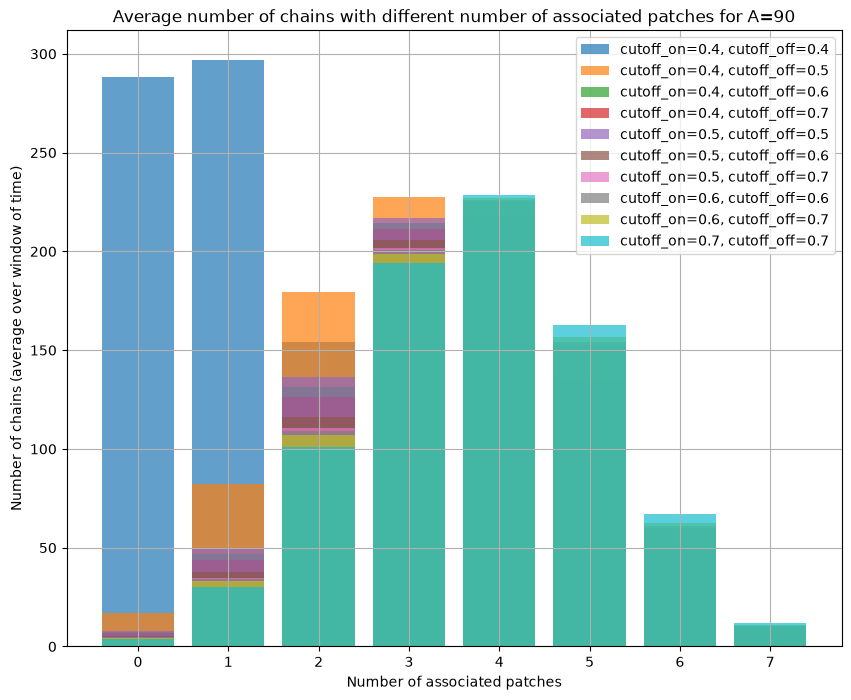

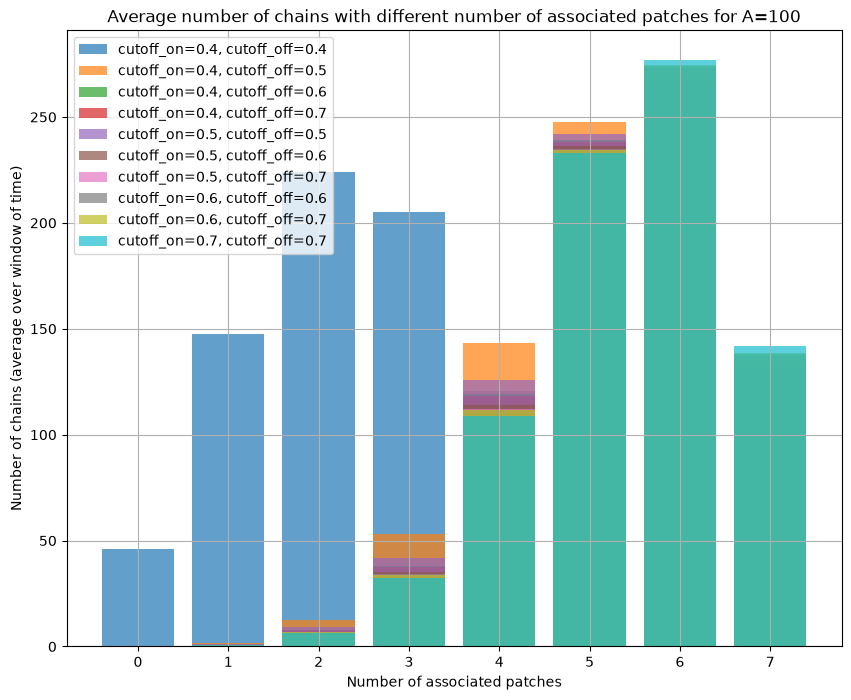

Did not find s=9 in the dataframe, setting num_associated to 0.
Did not find s=1 in the dataframe, setting num_associated to 0.
Did not find s=2 in the dataframe, setting num_associated to 0.
Did not find s=8 in the dataframe, setting num_associated to 0.
Did not find s=20 in the dataframe, setting num_associated to 0.
Did not find s=32 in the dataframe, setting num_associated to 0.
Did not find s=1 in the dataframe, setting num_associated to 0.
Did not find s=2 in the dataframe, setting num_associated to 0.
Did not find s=3 in the dataframe, setting num_associated to 0.
Did not find s=4 in the dataframe, setting num_associated to 0.
Did not find s=5 in the dataframe, setting num_associated to 0.
Did not find s=6 in the dataframe, setting num_associated to 0.
Did not find s=8 in the dataframe, setting num_associated to 0.
Did not find s=9 in the dataframe, setting num_associated to 0.
Did not find s=10 in the dataframe, setting num_associated to 0.
Did not find s=12 in the dataframe, s

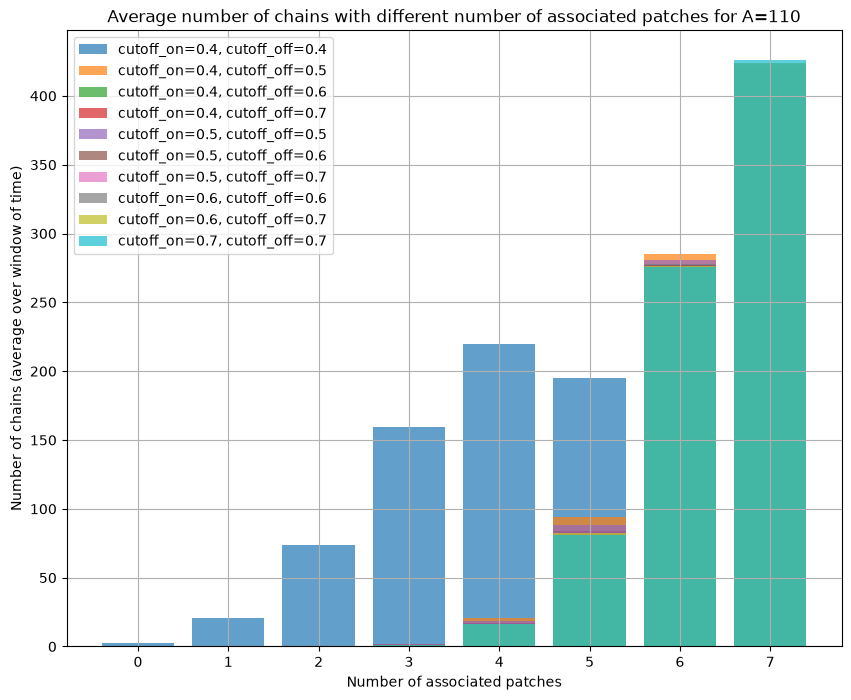

Did not find s=1 in the dataframe, setting num_associated to 0.
Did not find s=2 in the dataframe, setting num_associated to 0.
Did not find s=3 in the dataframe, setting num_associated to 0.
Did not find s=4 in the dataframe, setting num_associated to 0.
Did not find s=5 in the dataframe, setting num_associated to 0.
Did not find s=6 in the dataframe, setting num_associated to 0.
Did not find s=8 in the dataframe, setting num_associated to 0.
Did not find s=9 in the dataframe, setting num_associated to 0.
Did not find s=16 in the dataframe, setting num_associated to 0.
Did not find s=20 in the dataframe, setting num_associated to 0.
Did not find s=24 in the dataframe, setting num_associated to 0.
Did not find s=34 in the dataframe, setting num_associated to 0.
Did not find s=35 in the dataframe, setting num_associated to 0.
Did not find s=36 in the dataframe, setting num_associated to 0.
Did not find s=40 in the dataframe, setting num_associated to 0.
Did not find s=48 in the datafram

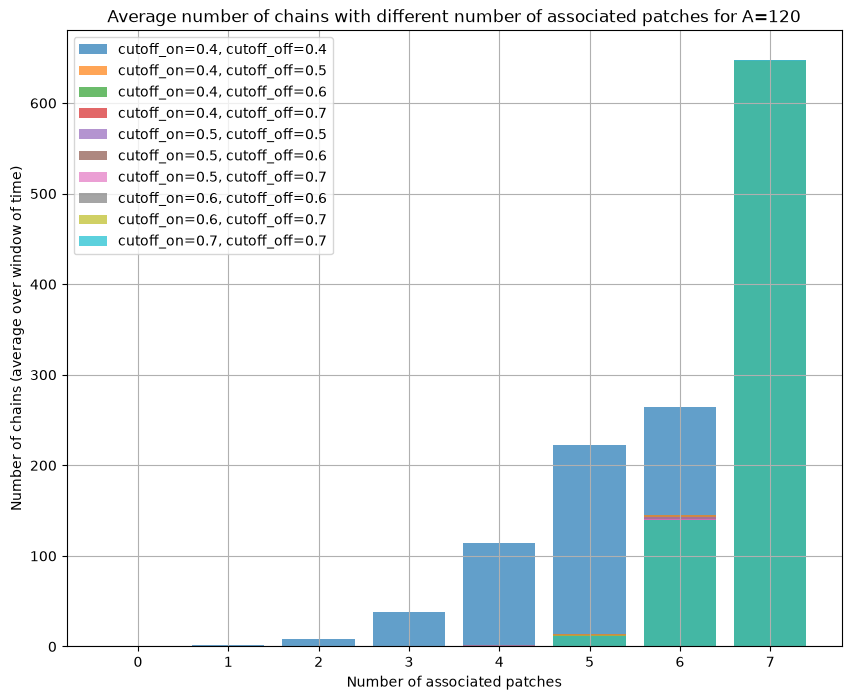

Did not find s=1 in the dataframe, setting num_associated to 0.
Did not find s=2 in the dataframe, setting num_associated to 0.
Did not find s=3 in the dataframe, setting num_associated to 0.
Did not find s=4 in the dataframe, setting num_associated to 0.
Did not find s=5 in the dataframe, setting num_associated to 0.
Did not find s=6 in the dataframe, setting num_associated to 0.
Did not find s=8 in the dataframe, setting num_associated to 0.
Did not find s=9 in the dataframe, setting num_associated to 0.
Did not find s=10 in the dataframe, setting num_associated to 0.
Did not find s=11 in the dataframe, setting num_associated to 0.
Did not find s=12 in the dataframe, setting num_associated to 0.
Did not find s=13 in the dataframe, setting num_associated to 0.
Did not find s=14 in the dataframe, setting num_associated to 0.
Did not find s=16 in the dataframe, setting num_associated to 0.
Did not find s=17 in the dataframe, setting num_associated to 0.
Did not find s=18 in the datafram

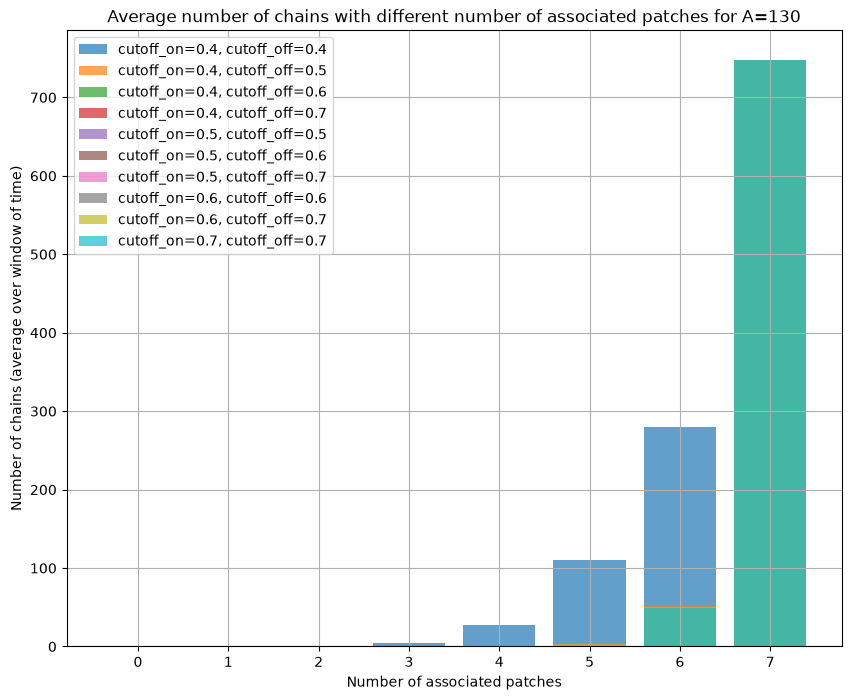

Did not find s=1 in the dataframe, setting num_associated to 0.
Did not find s=2 in the dataframe, setting num_associated to 0.
Did not find s=32 in the dataframe, setting num_associated to 0.
Did not find s=1 in the dataframe, setting num_associated to 0.
Did not find s=2 in the dataframe, setting num_associated to 0.
Did not find s=3 in the dataframe, setting num_associated to 0.
Did not find s=4 in the dataframe, setting num_associated to 0.
Did not find s=5 in the dataframe, setting num_associated to 0.
Did not find s=6 in the dataframe, setting num_associated to 0.
Did not find s=7 in the dataframe, setting num_associated to 0.
Did not find s=8 in the dataframe, setting num_associated to 0.
Did not find s=9 in the dataframe, setting num_associated to 0.
Did not find s=10 in the dataframe, setting num_associated to 0.
Did not find s=11 in the dataframe, setting num_associated to 0.
Did not find s=12 in the dataframe, setting num_associated to 0.
Did not find s=13 in the dataframe, 

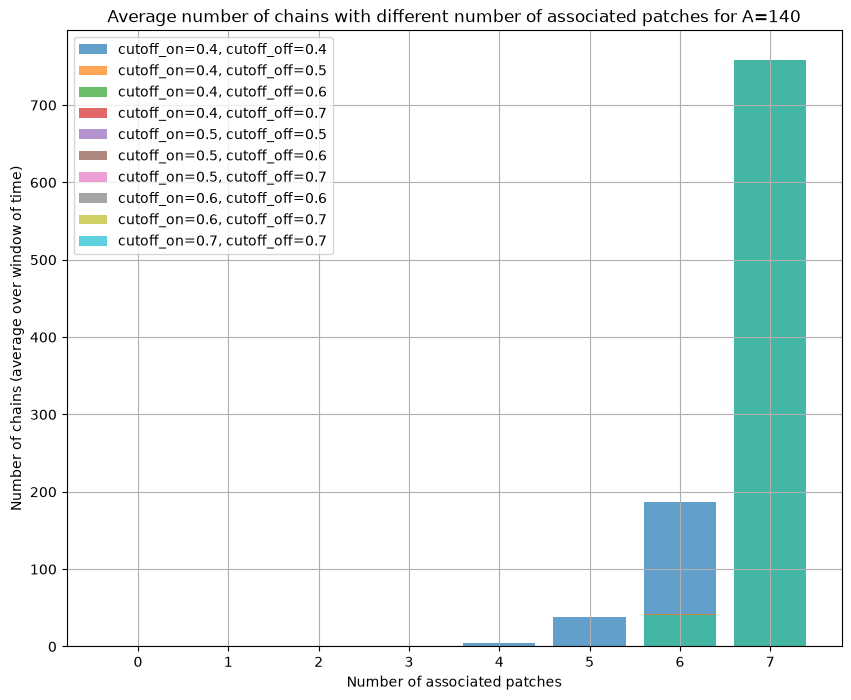

Did not find s=1 in the dataframe, setting num_associated to 0.
Did not find s=2 in the dataframe, setting num_associated to 0.
Did not find s=4 in the dataframe, setting num_associated to 0.
Did not find s=5 in the dataframe, setting num_associated to 0.
Did not find s=6 in the dataframe, setting num_associated to 0.
Did not find s=8 in the dataframe, setting num_associated to 0.
Did not find s=10 in the dataframe, setting num_associated to 0.
Did not find s=16 in the dataframe, setting num_associated to 0.
Did not find s=18 in the dataframe, setting num_associated to 0.
Did not find s=32 in the dataframe, setting num_associated to 0.
Did not find s=33 in the dataframe, setting num_associated to 0.
Did not find s=36 in the dataframe, setting num_associated to 0.
Did not find s=40 in the dataframe, setting num_associated to 0.
Did not find s=48 in the dataframe, setting num_associated to 0.
Did not find s=64 in the dataframe, setting num_associated to 0.
Did not find s=65 in the datafr

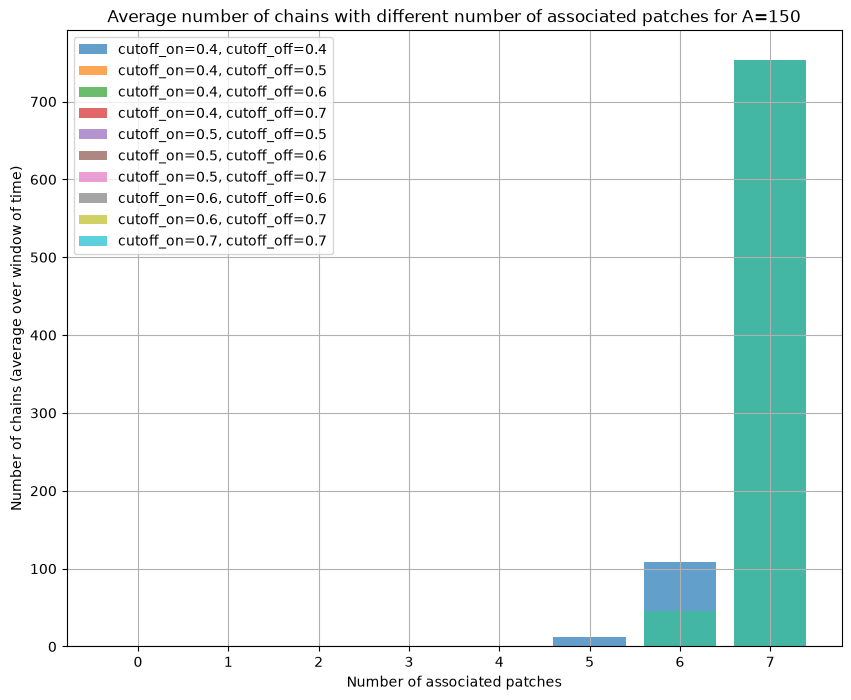

In [36]:
# cutoffs = [0.4, 0.5, 0.6, 0.7]

# As = [90, 100, 110, 120, 130]

times = np.arange(0, 20, 0.002) # 10000 samples
# s=2

for A in As:
    fig = plt.figure(figsize=(10,8))
    for cutoff_on in cutoffs:
        for cutoff_off in cutoffs:
            if cutoff_on <= cutoff_off: # only process lifetimes for cutoff_on < cutoff_off to avoid duplicates
                s_counts_df = pd.read_csv(f"data/s_states/buffered_s_counts_A{A}_cutoff_on{cutoff_on}_cutoff_off{cutoff_off}_r0_0.25.csv")
                num_associated_list = {}
                for s in range(0, 128, 1):
                    try:
                        num_associated = count_associated(s)
                        if num_associated not in num_associated_list:
                            num_associated_list[num_associated] = 0
                        num_associated_list[num_associated] += np.mean(s_counts_df[f'{s}'][100:])  # Average number density of chains in state s
                    except KeyError:
                        num_associated_list[count_associated(s)] = 0
                        print(f"Did not find s={s} in the dataframe, setting num_associated to 0.")
                plt.bar(num_associated_list.keys(), num_associated_list.values(), alpha=0.7, label=f"cutoff_on={cutoff_on}, cutoff_off={cutoff_off}")

                # plt.plot(times[:len(s_counts_df)], s_counts_df[f'{s}'], label=f"cutoff_on={cutoff_on}, cutoff_off={cutoff_off}")




    plt.xlabel(f"Number of associated patches")
    plt.ylabel(f"Number of chains (average over window of time)")
    # print(f"nu_s(s={s}) = {nu_s(s, 1/5.58, 1/7.27, 5, 31, 0.0274)}")
    # plt.axhline(nu_s(s, 1/11.09, 1/5.42, 5, 31, 0.0274), color='r', linestyle='--', label=f"nu_s(s={s})")
    plt.title(f"Average number of chains with different number of associated patches for A={A}")
    plt.grid(True)
    plt.legend()
    plt.show()

## Calculating $\nu^s$ spectrum for an input $\alpha, \beta$

In [37]:
def nu_s_spectrum(alpha, beta, M, N_b, n_c=1):
    N_a = (N_b - 1) // M + 1
    s_spectrum = {}
    for s in range(0, 2**N_a):
        s_spectrum[s] = nu_s(s, alpha, beta, M, N_b, n_c)
    return s_spectrum


Let's look at A = 120 first, a midrange with some interactions. 

In [38]:
from scipy.stats import chisquare

def fit_nu_s_spectrum(A):
    lifetime_df = pd.read_csv("data/lifetimes/tau_lifetimes_spacing_5.csv")
    offtime_df = pd.read_csv("data/offtimes/tau_offtimes_spacing_5.csv")

    lowest_chisquare = float('inf')
    best_cutoff_on = None
    best_cutoff_off = None
    for cutoff_on in cutoffs:
        for cutoff_off in cutoffs:
            if cutoff_on <= cutoff_off: # only process lifetimes for cutoff_on < cutoff_off to avoid duplicates
                try:
                    fig = plt.figure(figsize=(10,8))

                    s_counts_df = pd.read_csv(f"data/s_states/buffered_s_counts_A{A}_cutoff_on{cutoff_on}_cutoff_off{cutoff_off}_r0_0.25.csv")
                    s_list = np.arange(0, 128, 1)
                    nu_s_avg_list = []
                    for s in s_list:
                        try:
                            nu_s_avg_list.append(np.mean(s_counts_df[f'{s}'][100:]) / box_volume)  # Average number density of chains in state s
                        except KeyError:
                            nu_s_avg_list.append(0)
                            # print(f"Did not find s={s} in the dataframe, setting nu_s_avg to 0.")
                    plt.plot(s_list, nu_s_avg_list, label=f"cutoff_on={cutoff_on}, cutoff_off={cutoff_off}")

                    # plt.plot(times[:len(s_counts_df)], s_counts_df[f'{s}'], label=f"cutoff_on={cutoff_on}, cutoff_off={cutoff_off}")
                
                    print(offtime_df.loc[(offtime_df['A'] == A) & (offtime_df['cutoff_on'] == cutoff_on)  & (offtime_df['cutoff_off'] == cutoff_off), 'tau_2'])
                    tau_on = offtime_df.loc[(offtime_df['A'] == A) & (offtime_df['cutoff_on'] == cutoff_on) & (offtime_df['cutoff_off'] == cutoff_off), 'tau_2'].values[0]
                    tau_off = lifetime_df.loc[(lifetime_df['A'] == A) & (lifetime_df['cutoff_on'] == cutoff_on) & (lifetime_df['cutoff_off'] == cutoff_off), 'tau_2'].values[0]

                    alpha = 1 / tau_on
                    beta = 1 / tau_off

                    nu_s_spectrum_dict = nu_s_spectrum(alpha, beta, 5, 31, n_c=0.0274)
                    plt.plot(nu_s_spectrum_dict.keys(), nu_s_spectrum_dict.values(), color='red', linestyle='--', label=f"calculated nu_s(s) w/ alpha={alpha:.4f}, beta={beta:.4f}")
                    # print(len(nu_s_avg_list))
                    # print(len(nu_s_spectrum_dict.values()))
                    calc_chisquare = chisquare(nu_s_avg_list, list(nu_s_spectrum_dict.values()), sum_check=False)[0]
                    if calc_chisquare < lowest_chisquare:
                        lowest_chisquare = calc_chisquare
                        best_cutoff_on = cutoff_on
                        best_cutoff_off = cutoff_off
                    print("chi squared for {cutoff_on} {cutoff_off} is {chi2}".format(cutoff_on=cutoff_on, cutoff_off=cutoff_off, chi2=calc_chisquare))
                except Exception as e:
                    print(f"Error for A={A}, cutoff_on={cutoff_on}, cutoff_off={cutoff_off}, exception: {e}")
                
                plt.xlabel(f"s (association state)")
                plt.ylabel(f"Number density of chains (average over window of time)")
                plt.title(f"Average number density of chains in association states for A={A} compared with theoretical nu_s(s)")
                plt.grid(True)
                plt.legend()
                plt.show()
    print(f"Lowest chi squared value: {lowest_chisquare} for cutoff_on={best_cutoff_on}, cutoff_off={best_cutoff_off}")

## Fit for $A=90$

30    16.327626
Name: tau_2, dtype: float64
chi squared for 0.4 0.4 is 222028.31580810645


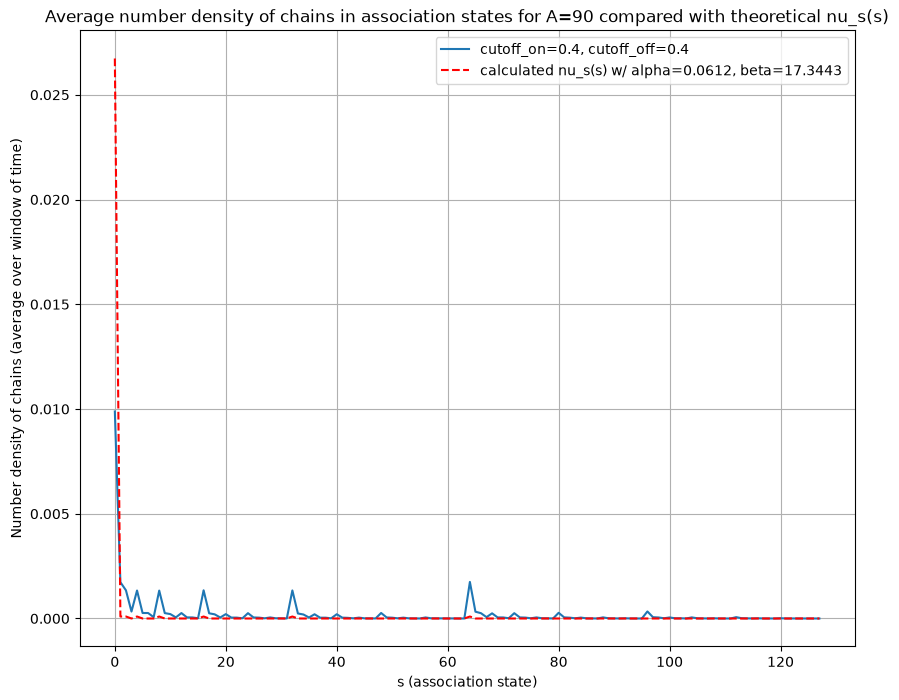

31    16.338674
Name: tau_2, dtype: float64
chi squared for 0.4 0.5 is 1.265377287219534


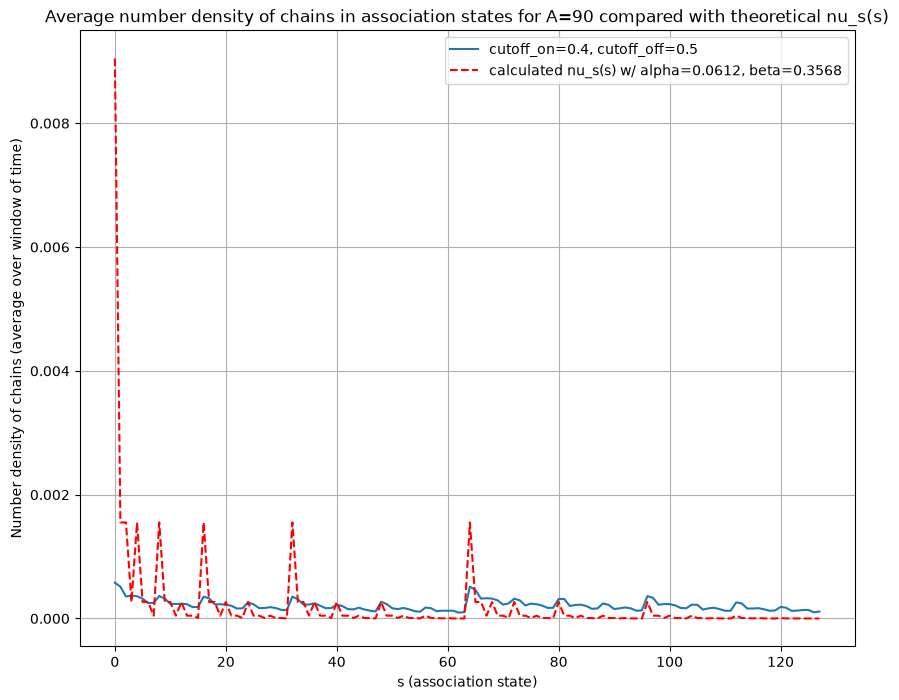

32    16.396852
Name: tau_2, dtype: float64
chi squared for 0.4 0.6 is 0.004582840798459253


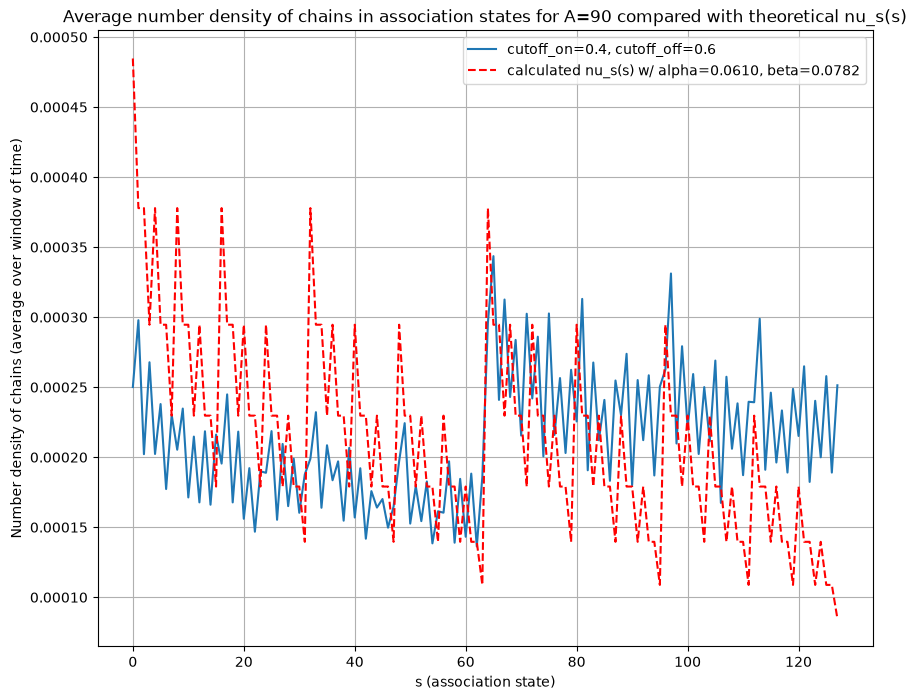

33    15.941374
Name: tau_2, dtype: float64
chi squared for 0.4 0.7 is 0.0012638183872352236


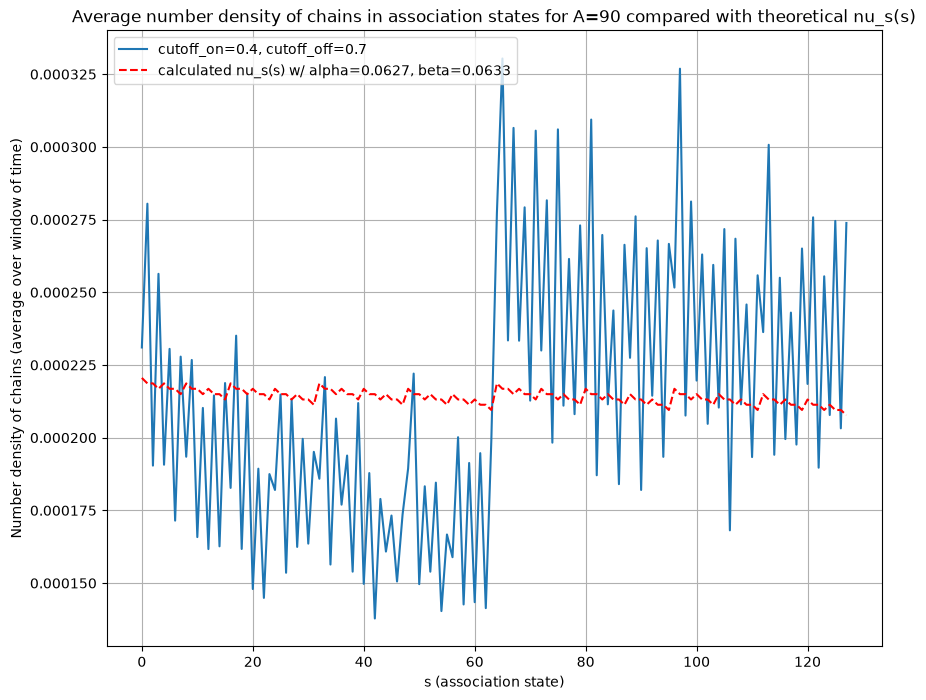

34    14.858423
Name: tau_2, dtype: float64
chi squared for 0.5 0.5 is 2.503310490063888


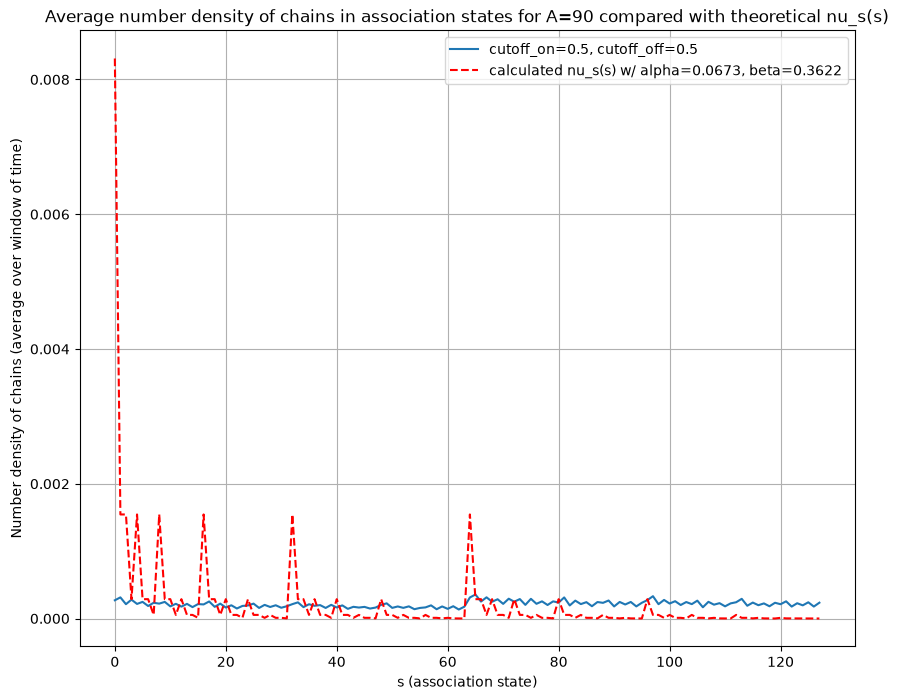

35    14.798466
Name: tau_2, dtype: float64
chi squared for 0.5 0.6 is 0.004062807140238205


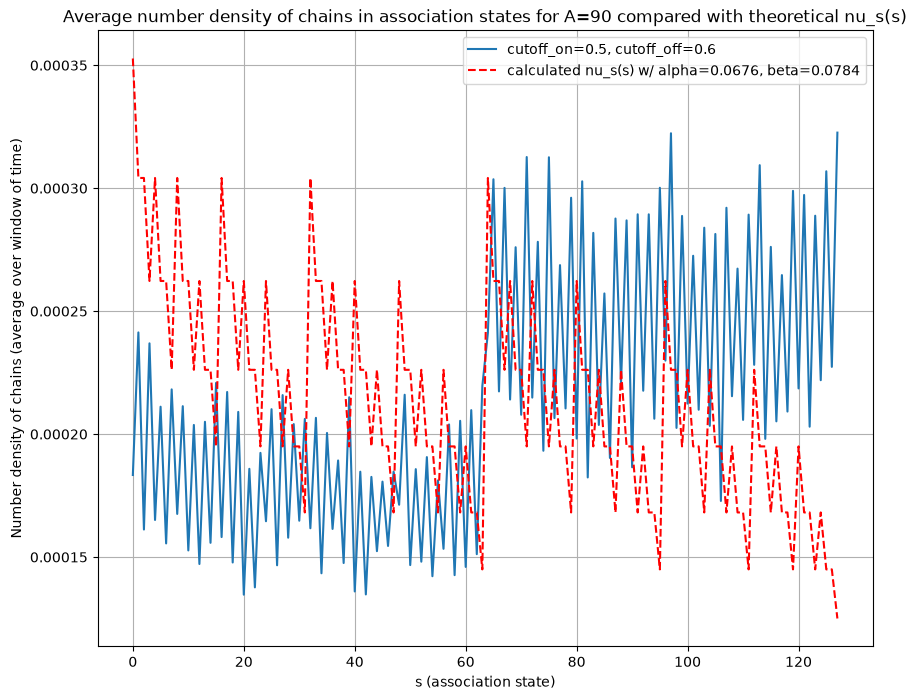

36    14.355393
Name: tau_2, dtype: float64
chi squared for 0.5 0.7 is 0.001262142863531377


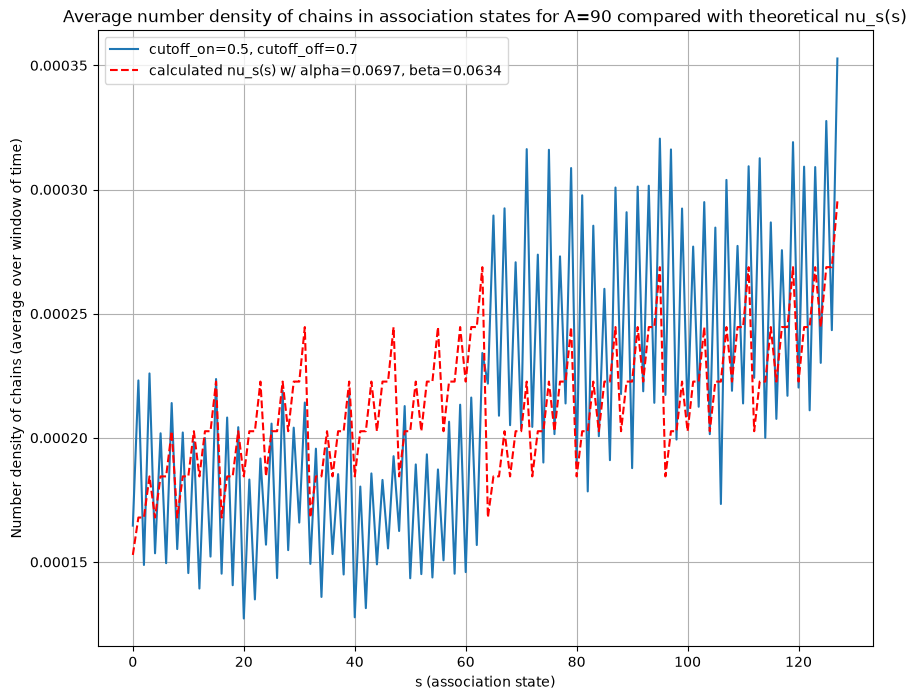

37    14.022688
Name: tau_2, dtype: float64
chi squared for 0.6 0.6 is 0.0037137762583566523


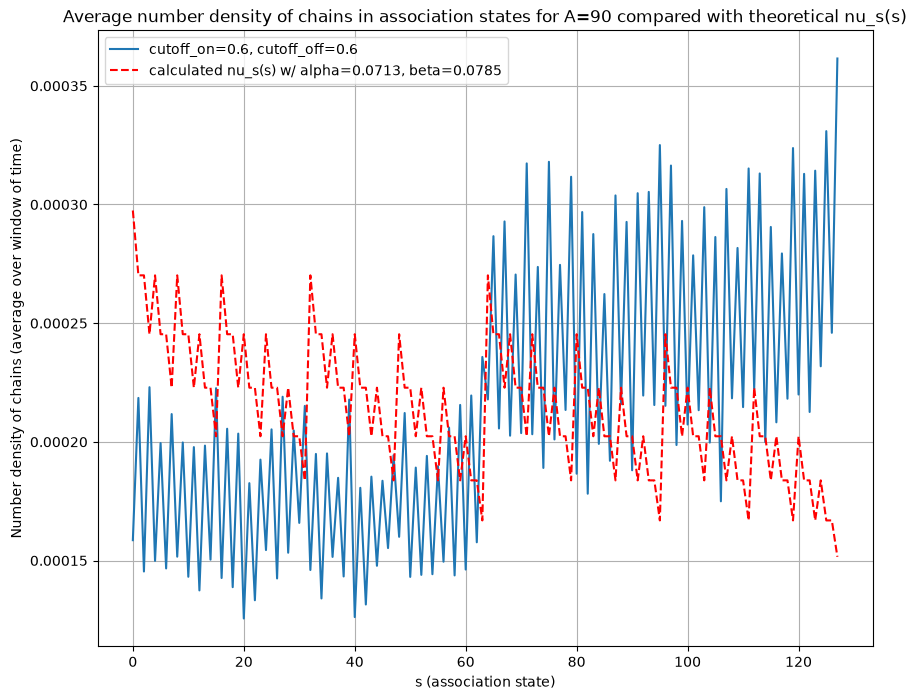

38    14.121052
Name: tau_2, dtype: float64
chi squared for 0.6 0.7 is 0.001282743393186799


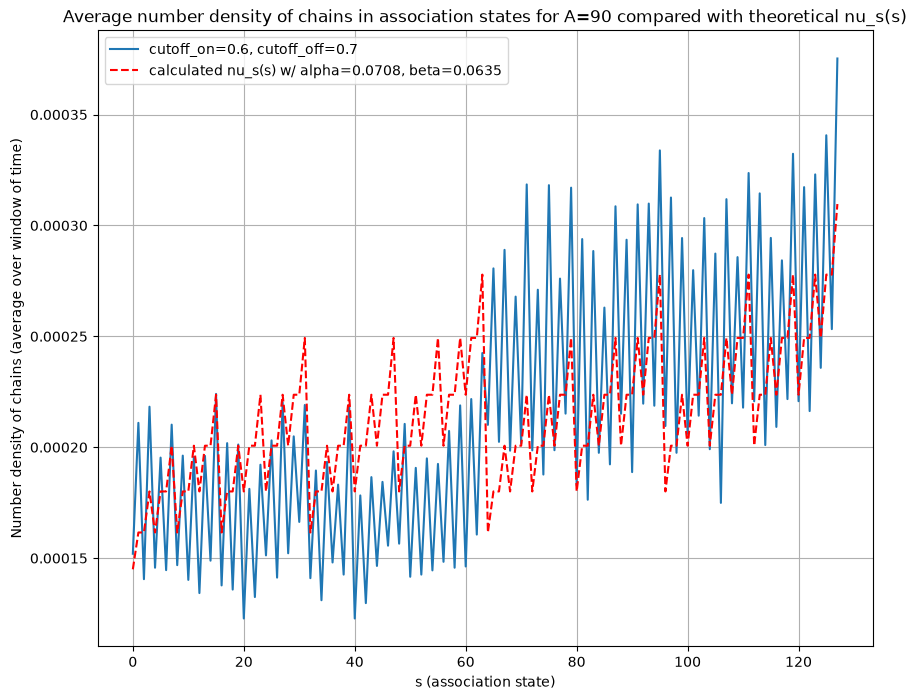

39    10.578865
Name: tau_2, dtype: float64
chi squared for 0.7 0.7 is 0.0044220425676980805


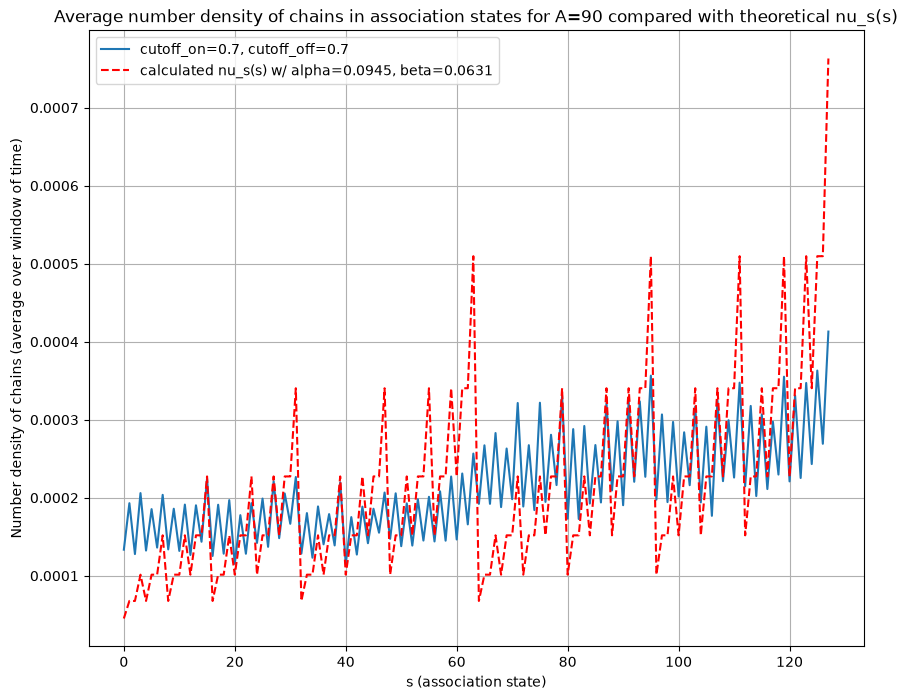

Lowest chi squared value: 0.001262142863531377 for cutoff_on=0.5, cutoff_off=0.7
40    28.469369
Name: tau_2, dtype: float64
chi squared for 0.4 0.4 is 20317467166.977215


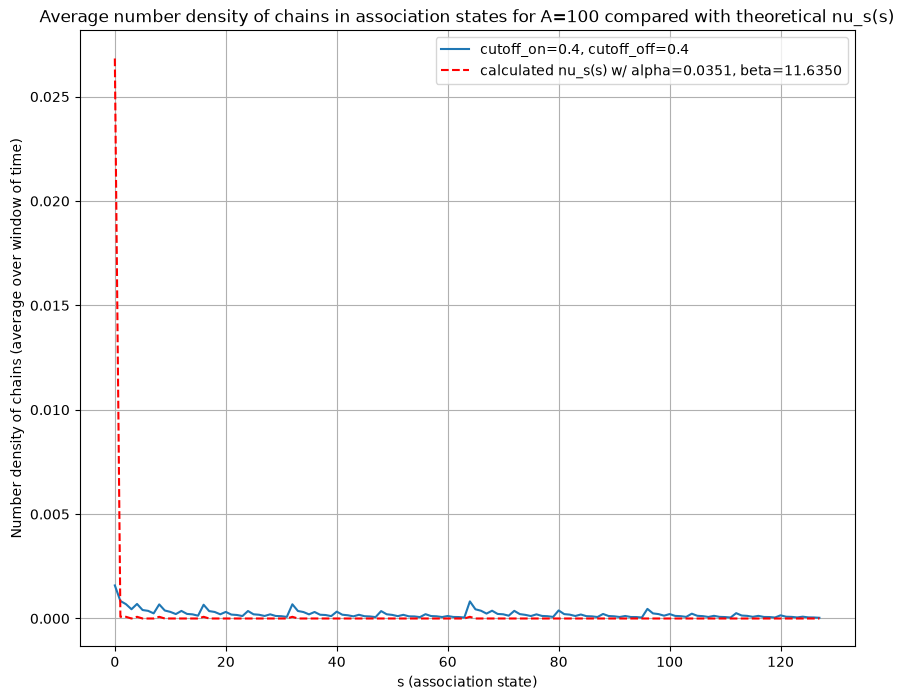

41    28.456748
Name: tau_2, dtype: float64
chi squared for 0.4 0.5 is 49.911653294376315


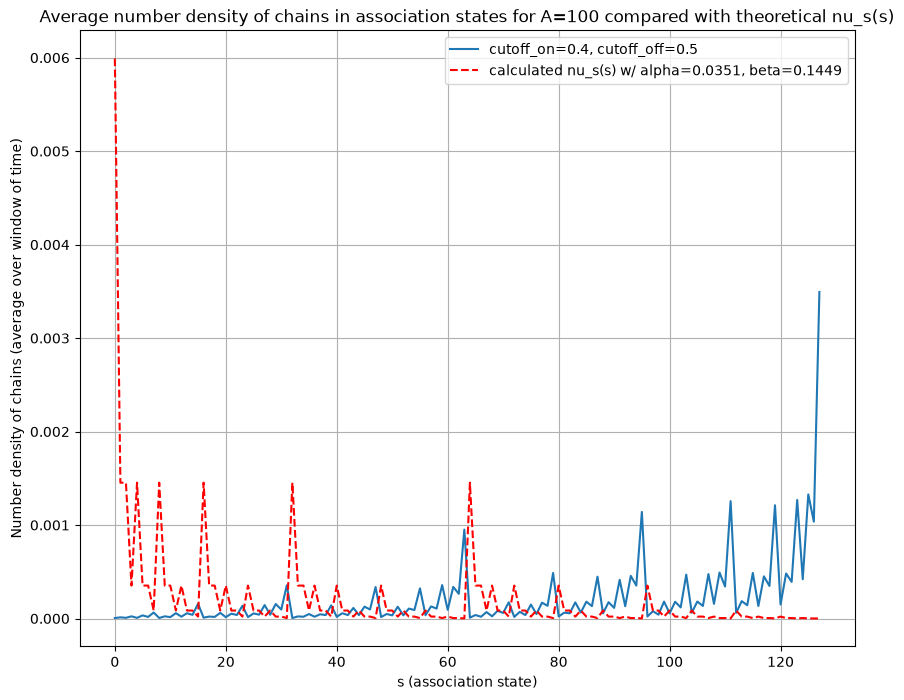

42    28.584898
Name: tau_2, dtype: float64
chi squared for 0.4 0.6 is 0.016403472606322366


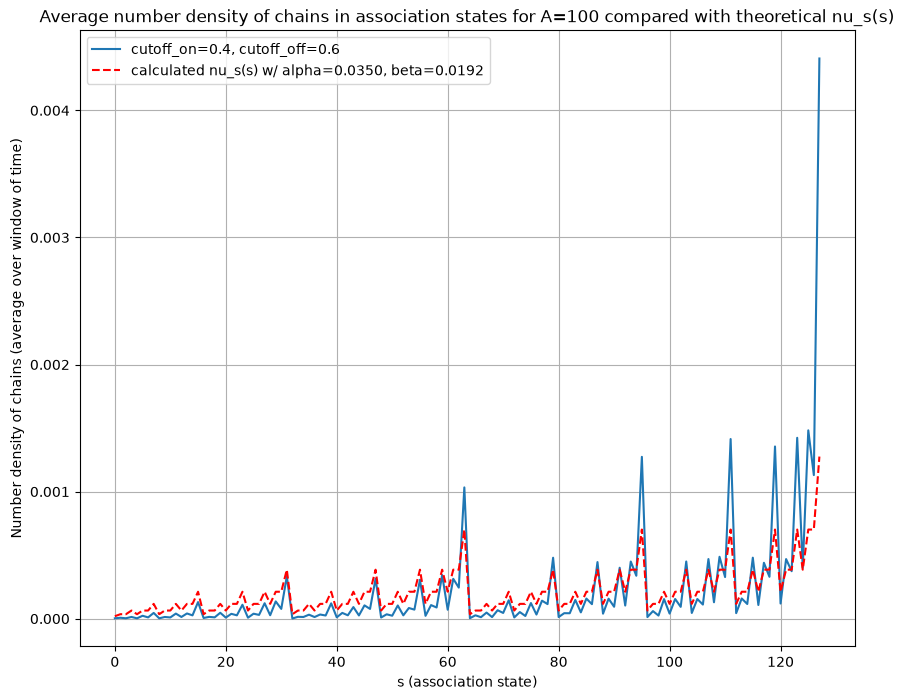

43    28.319809
Name: tau_2, dtype: float64
chi squared for 0.4 0.7 is 0.010483507794974272


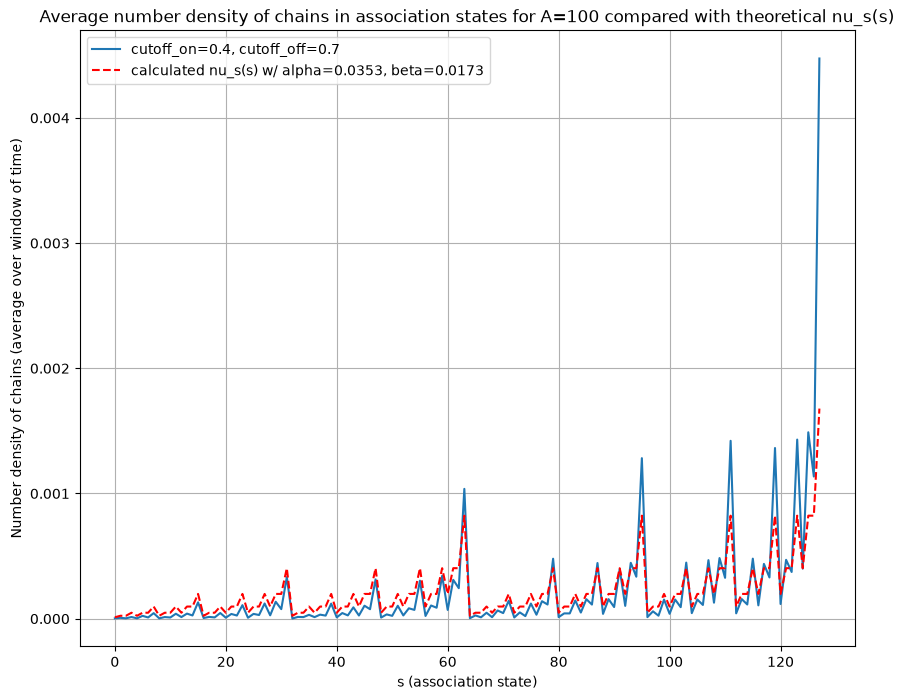

44    27.302598
Name: tau_2, dtype: float64
chi squared for 0.5 0.5 is 47.27421153530665


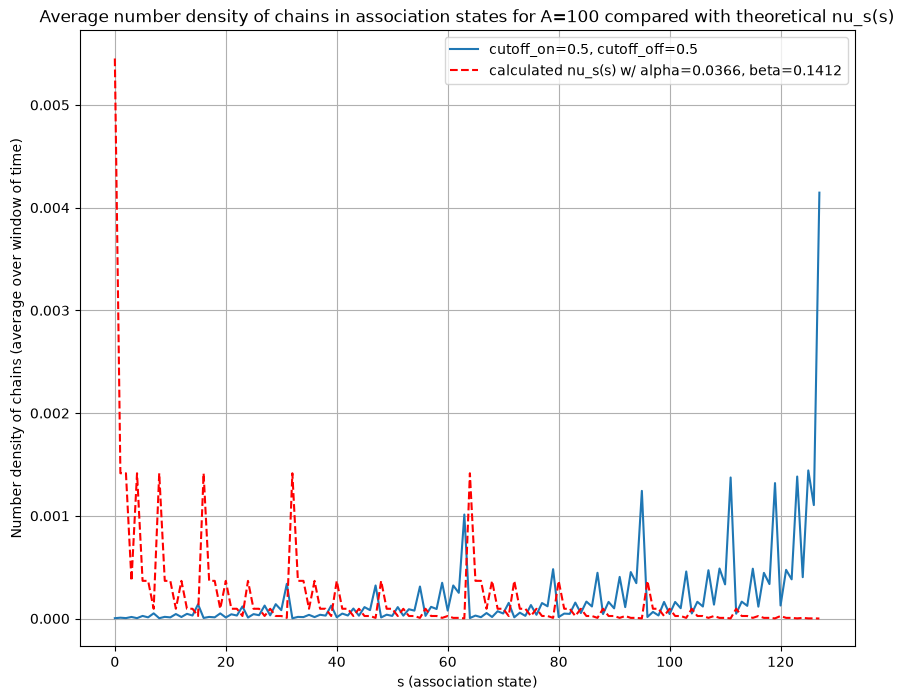

45    27.522938
Name: tau_2, dtype: float64
chi squared for 0.5 0.6 is 0.01293928886456114


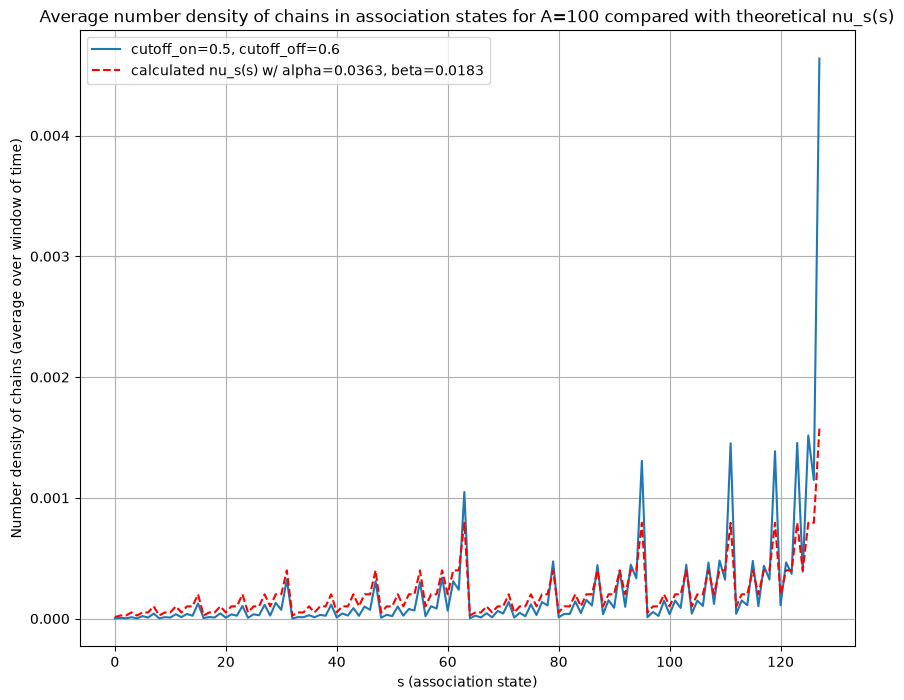

46    27.948427
Name: tau_2, dtype: float64
chi squared for 0.5 0.7 is 0.011408613442540454


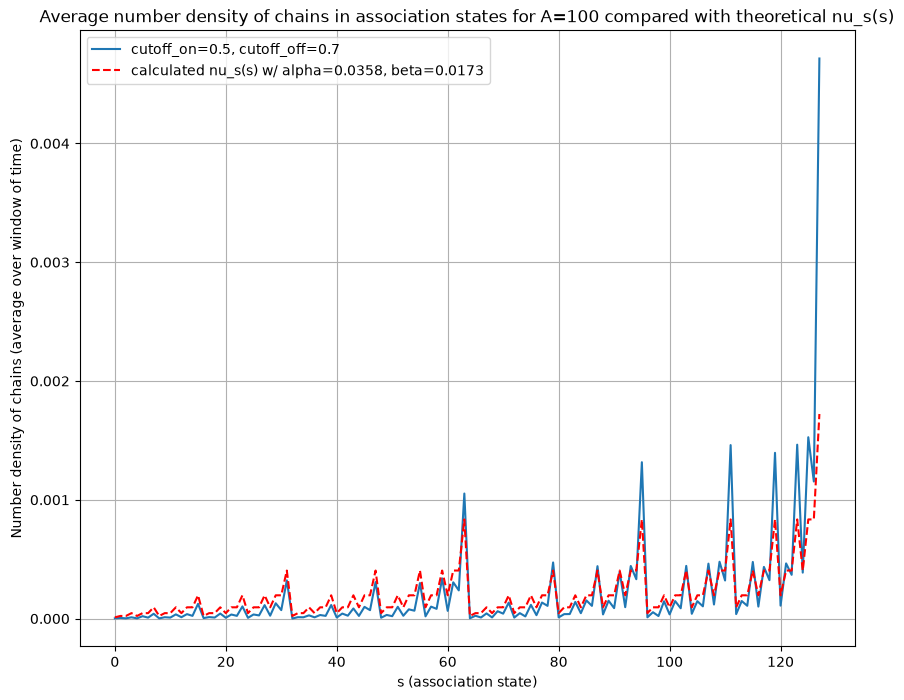

47    24.905873
Name: tau_2, dtype: float64
chi squared for 0.6 0.6 is 0.008522656942654168


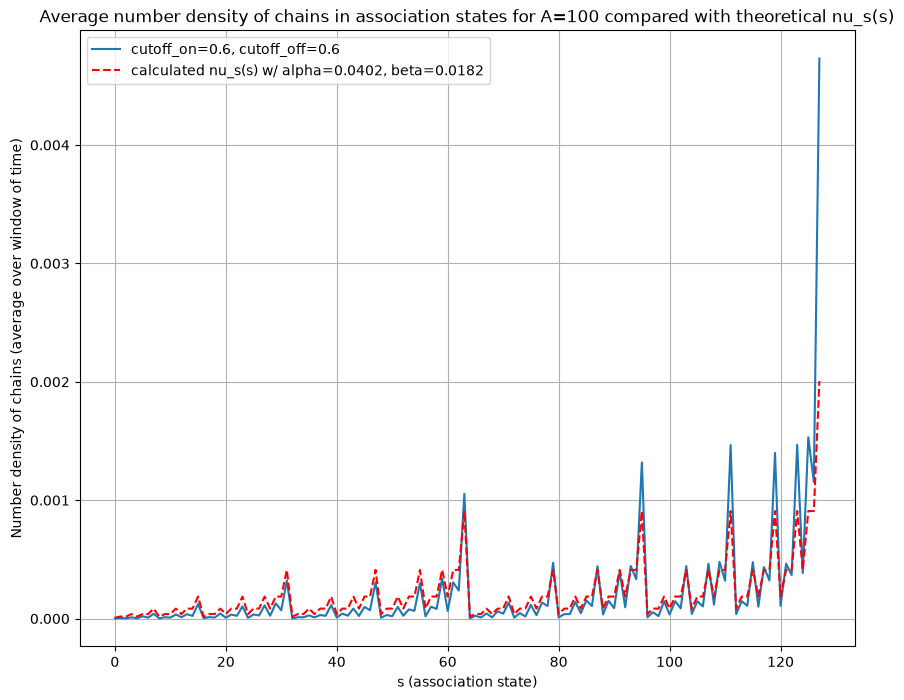

48    24.950661
Name: tau_2, dtype: float64
chi squared for 0.6 0.7 is 0.006871052428610773


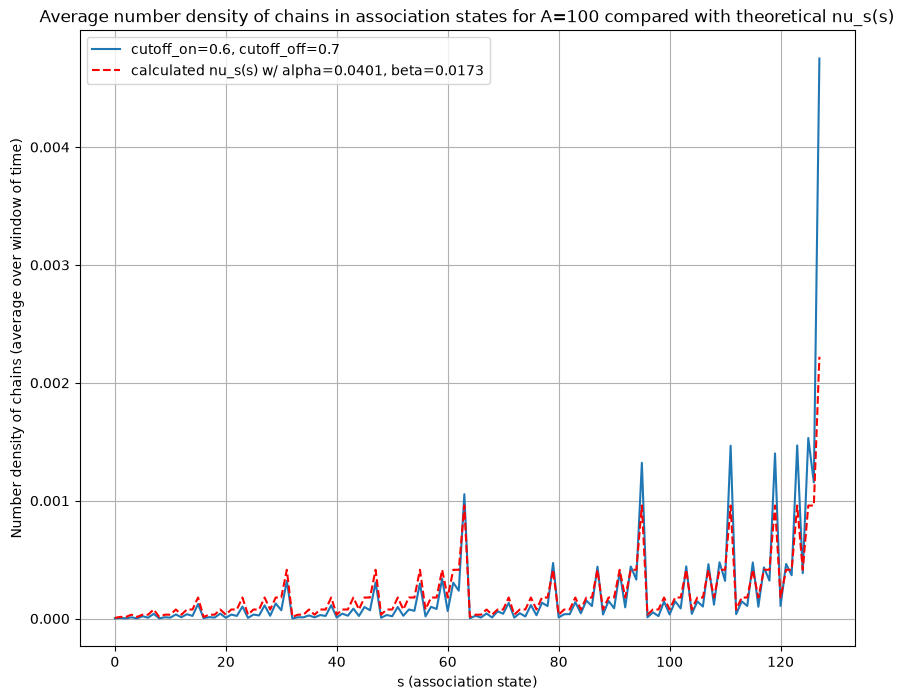

49    19.116657
Name: tau_2, dtype: float64
chi squared for 0.7 0.7 is 0.001530079361511374


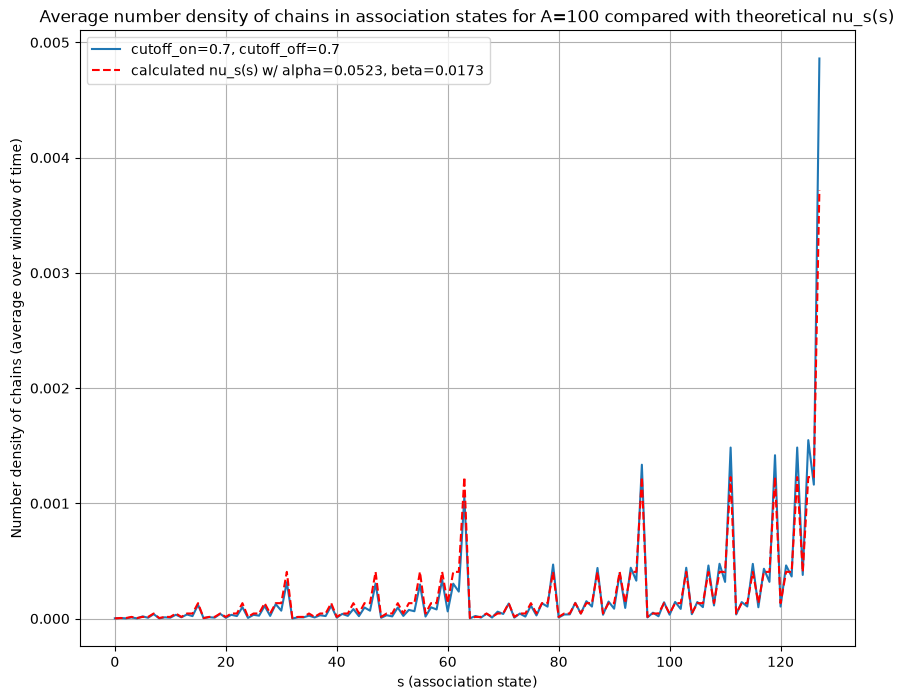

Lowest chi squared value: 0.001530079361511374 for cutoff_on=0.7, cutoff_off=0.7
50    70.845835
Name: tau_2, dtype: float64
chi squared for 0.4 0.4 is 8714923051973.087


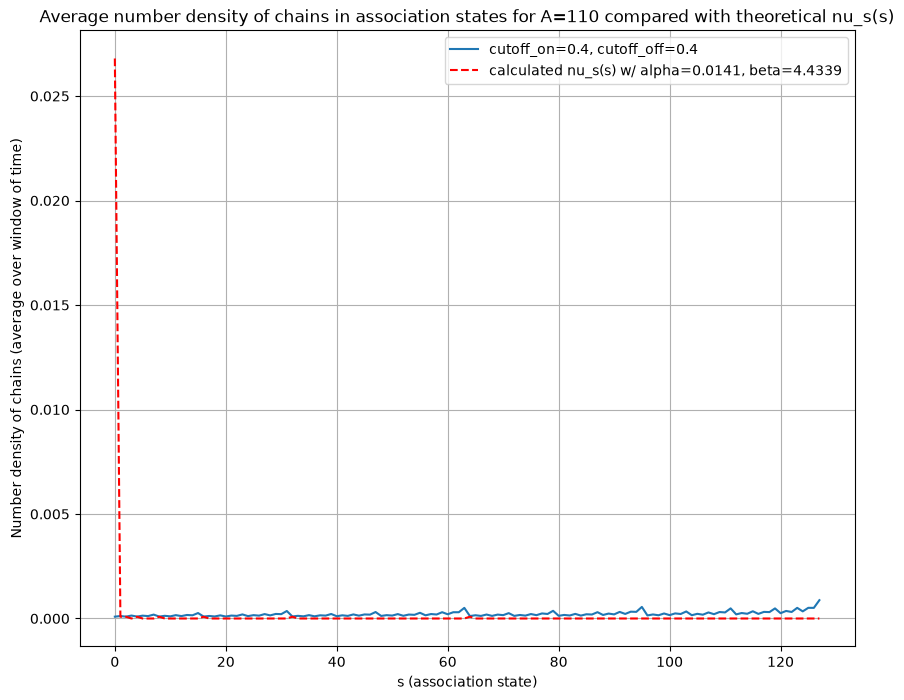

51    70.244884
Name: tau_2, dtype: float64
chi squared for 0.4 0.5 is 155.4582973696615


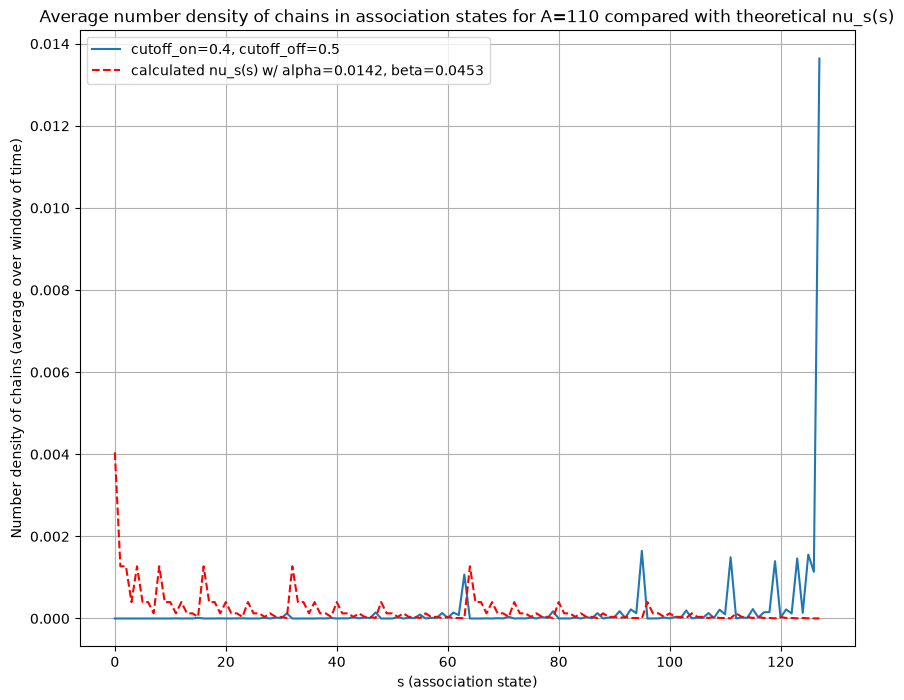

52    68.452743
Name: tau_2, dtype: float64
chi squared for 0.4 0.6 is 0.053238670656446


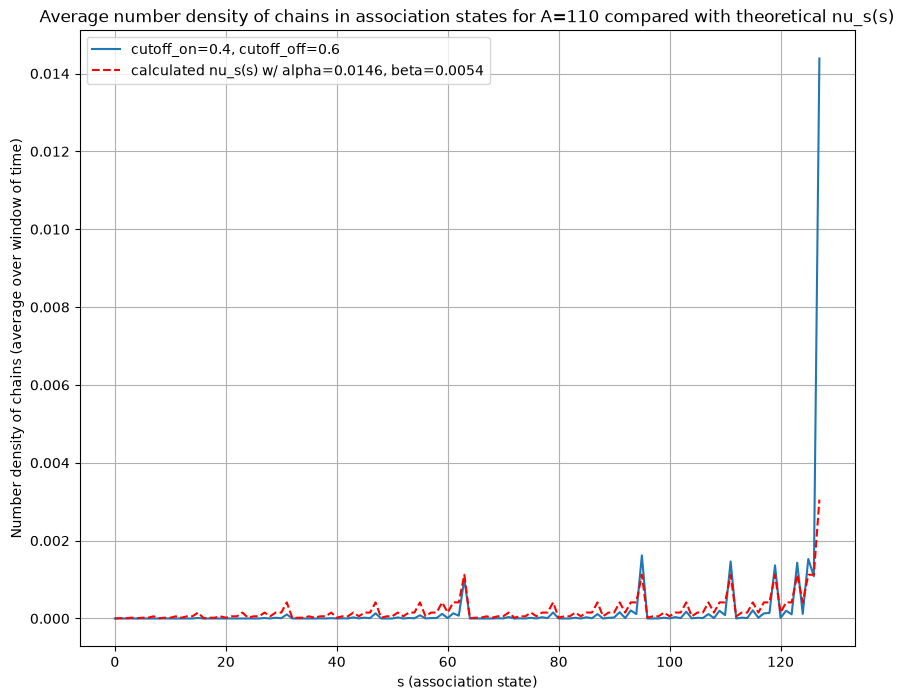

53    68.3695
Name: tau_2, dtype: float64
chi squared for 0.4 0.7 is 0.053297948947236023


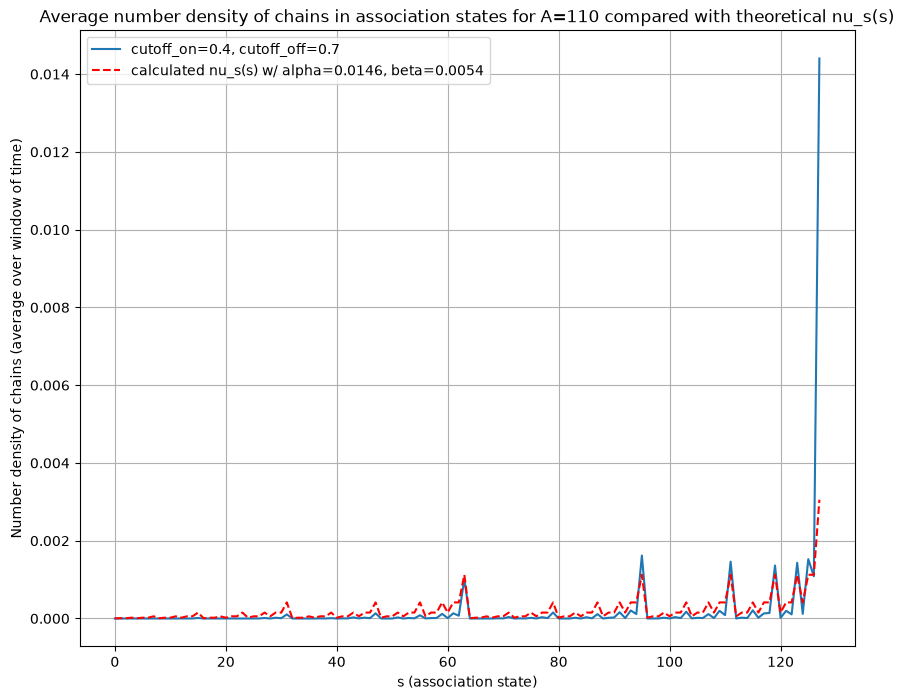

54    66.656666
Name: tau_2, dtype: float64
chi squared for 0.5 0.5 is 124.99798334464957


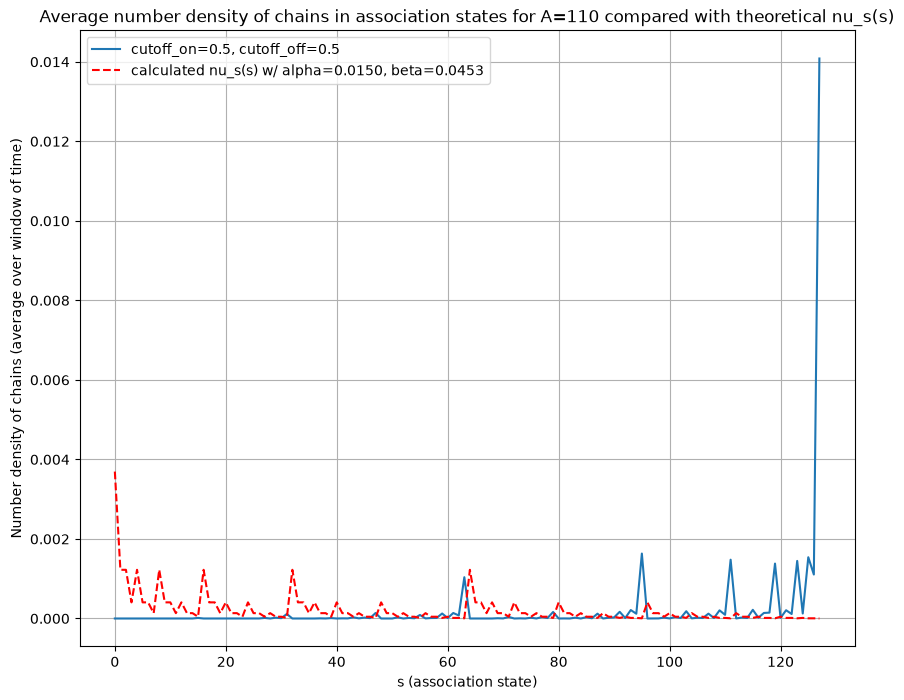

55    67.237919
Name: tau_2, dtype: float64
chi squared for 0.5 0.6 is 0.05147188820504199


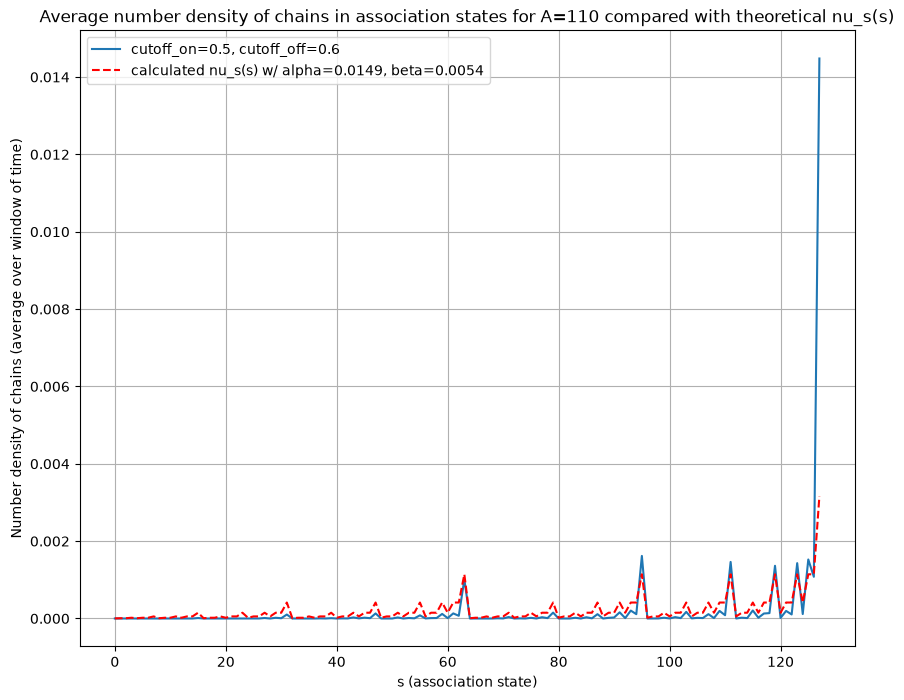

56    71.104062
Name: tau_2, dtype: float64
chi squared for 0.5 0.7 is 0.0597671814420246


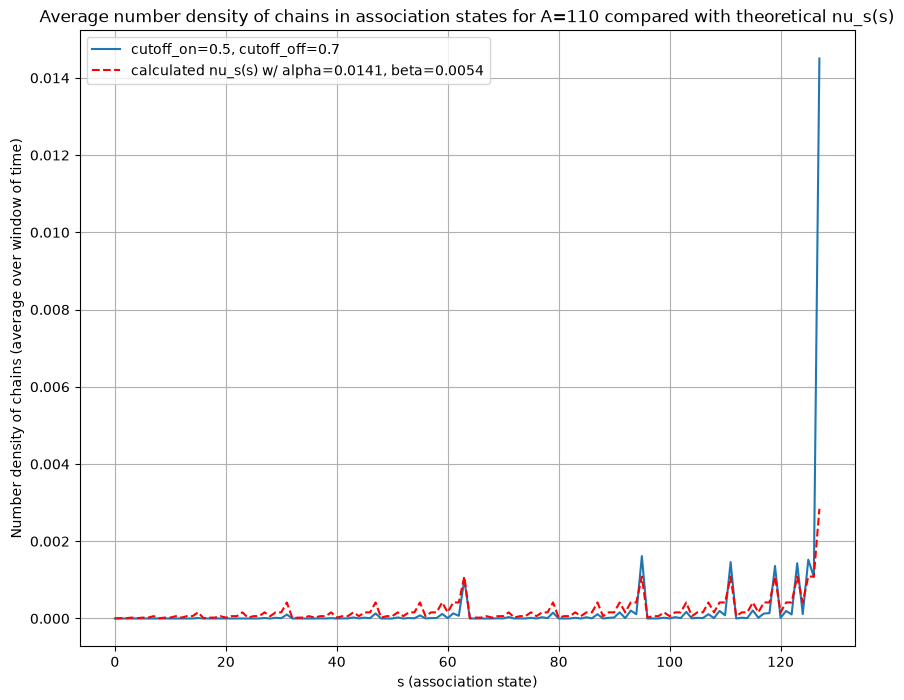

57    51.951296
Name: tau_2, dtype: float64
chi squared for 0.6 0.6 is 0.026593184940934843


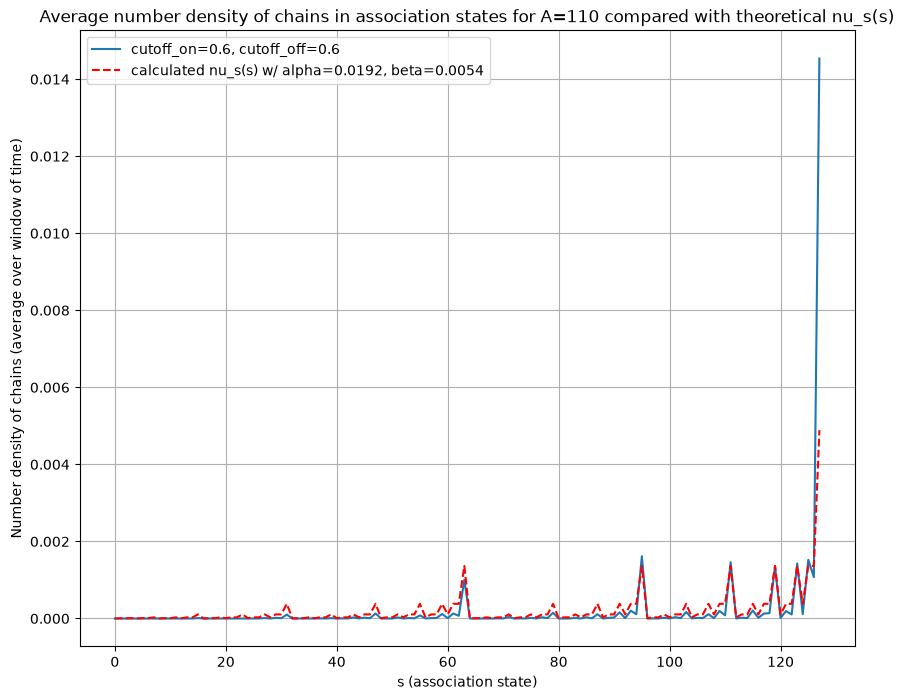

58    52.736139
Name: tau_2, dtype: float64
chi squared for 0.6 0.7 is 0.02762744350388544


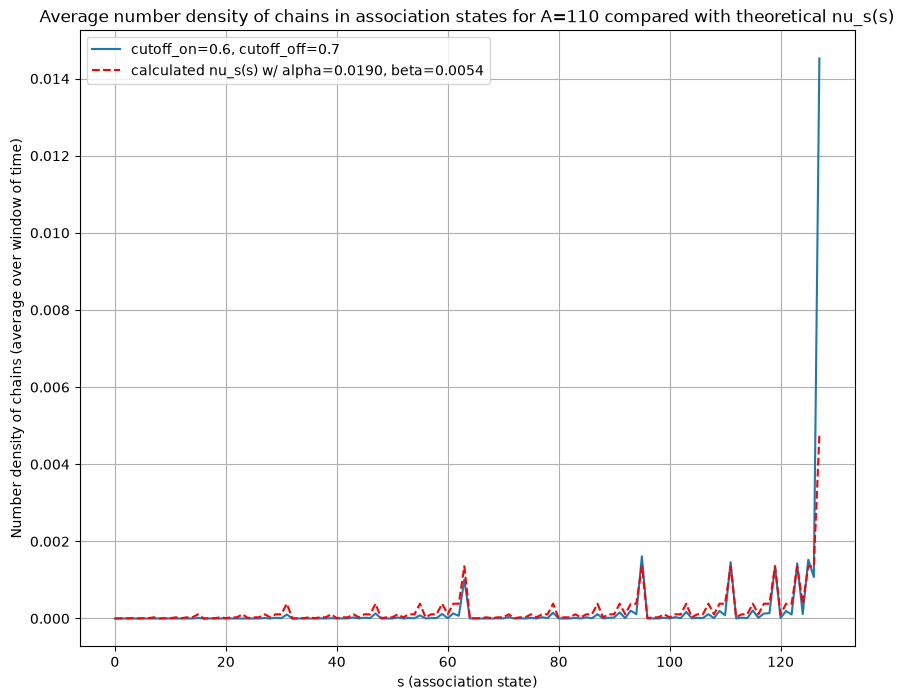

59    28.134687
Name: tau_2, dtype: float64
chi squared for 0.7 0.7 is 0.003964171165797171


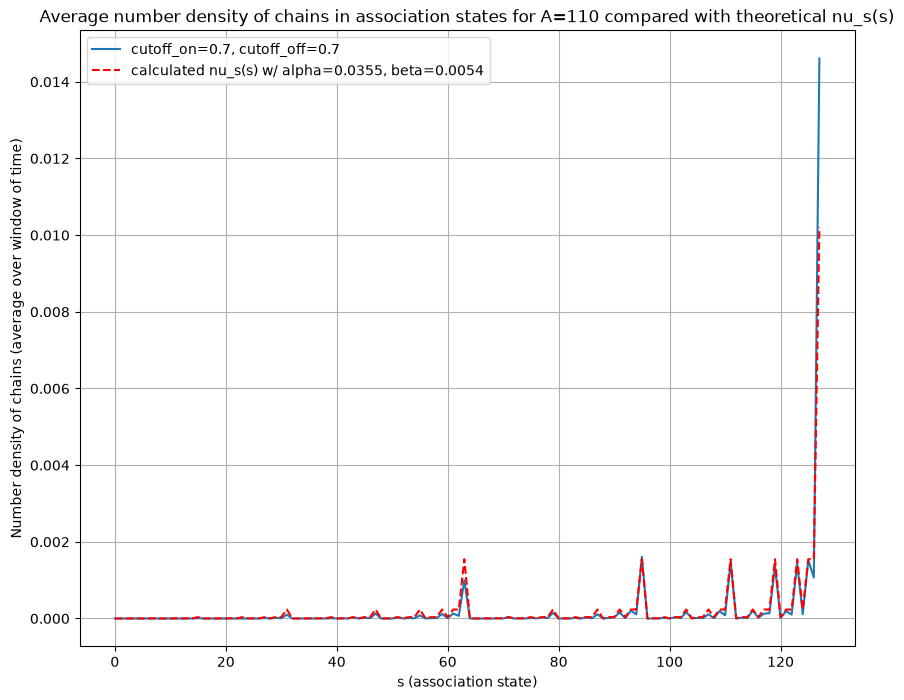

Lowest chi squared value: 0.003964171165797171 for cutoff_on=0.7, cutoff_off=0.7
60    168.2749
Name: tau_2, dtype: float64
chi squared for 0.4 0.4 is 78793739050654.78


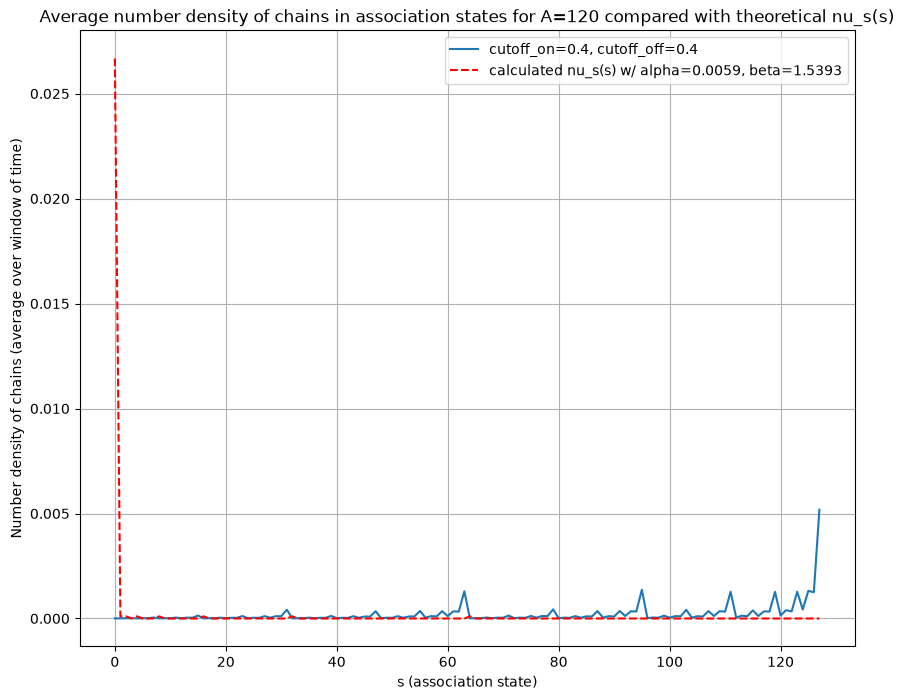

61    171.503074
Name: tau_2, dtype: float64
chi squared for 0.4 0.5 is 48.9676523409198


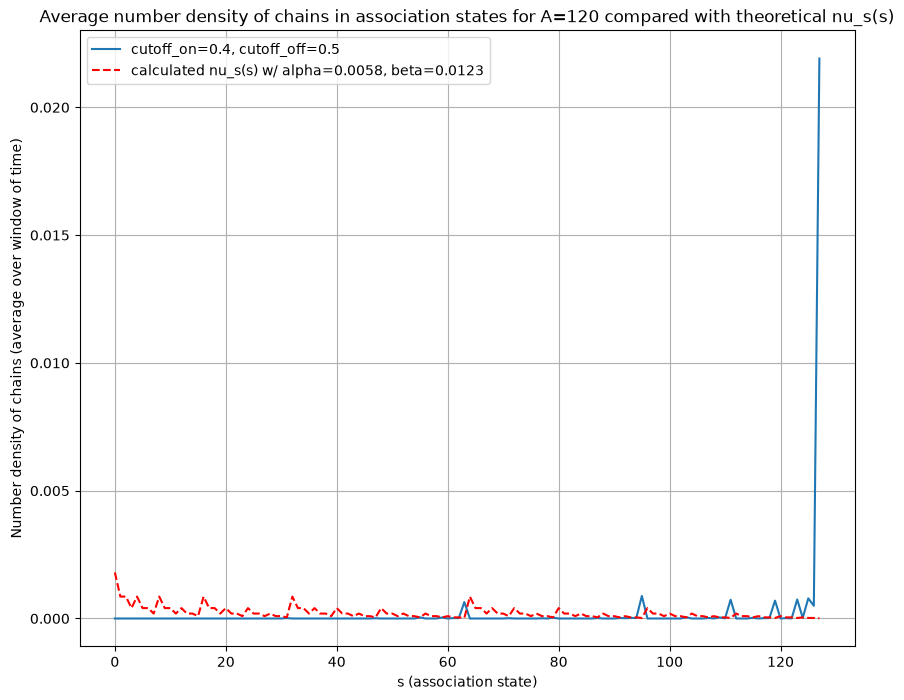

62    173.08711
Name: tau_2, dtype: float64
chi squared for 0.4 0.6 is 0.05787099513366105


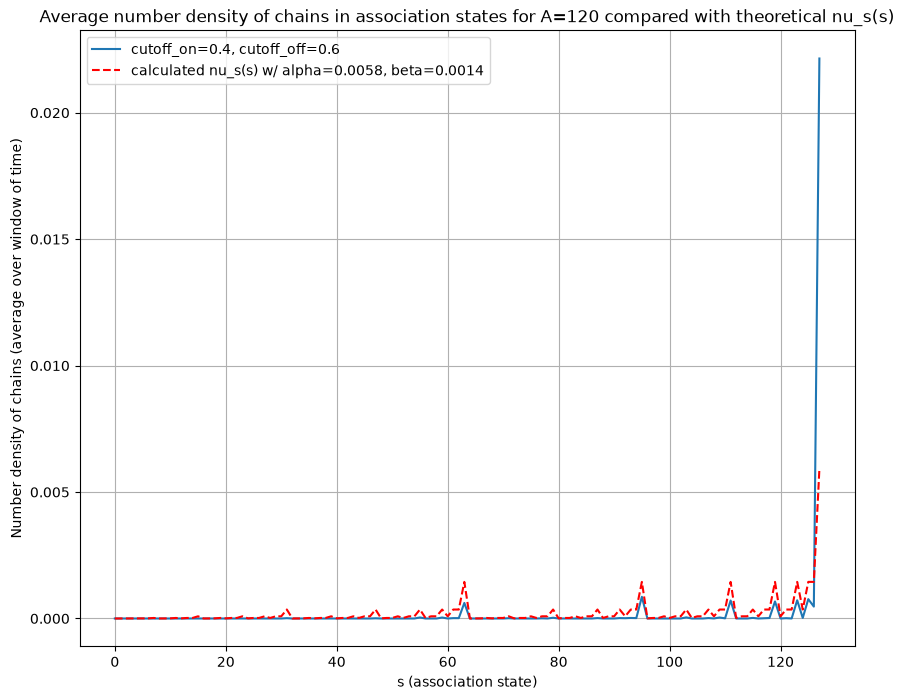

63    174.283592
Name: tau_2, dtype: float64
chi squared for 0.4 0.7 is 0.135066541737192


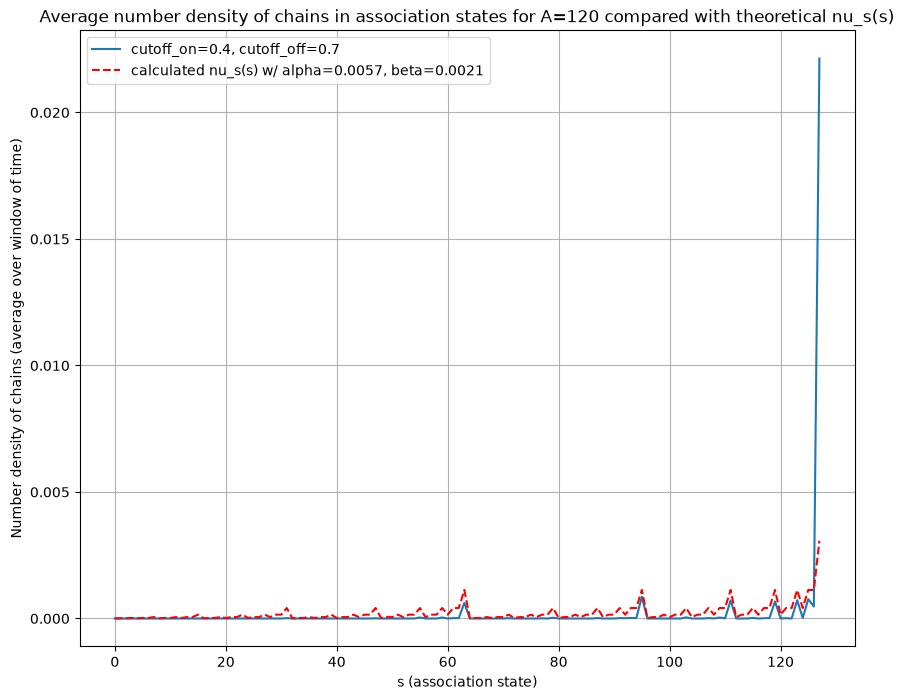

64    230.445323
Name: tau_2, dtype: float64
chi squared for 0.5 0.5 is 214.52644576919852


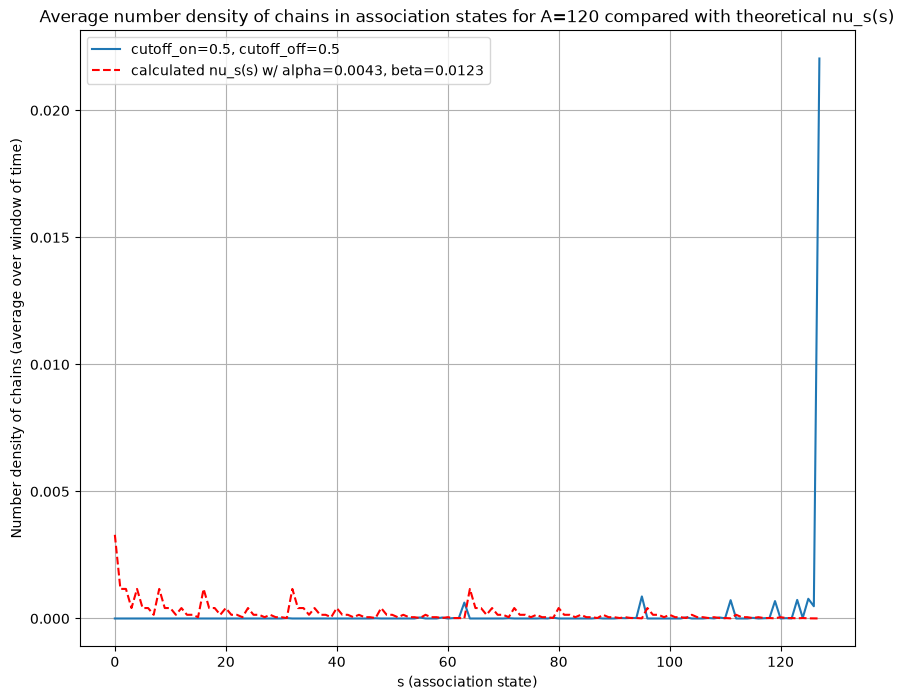

65    241.25181
Name: tau_2, dtype: float64
chi squared for 0.5 0.6 is 0.11538663626227423


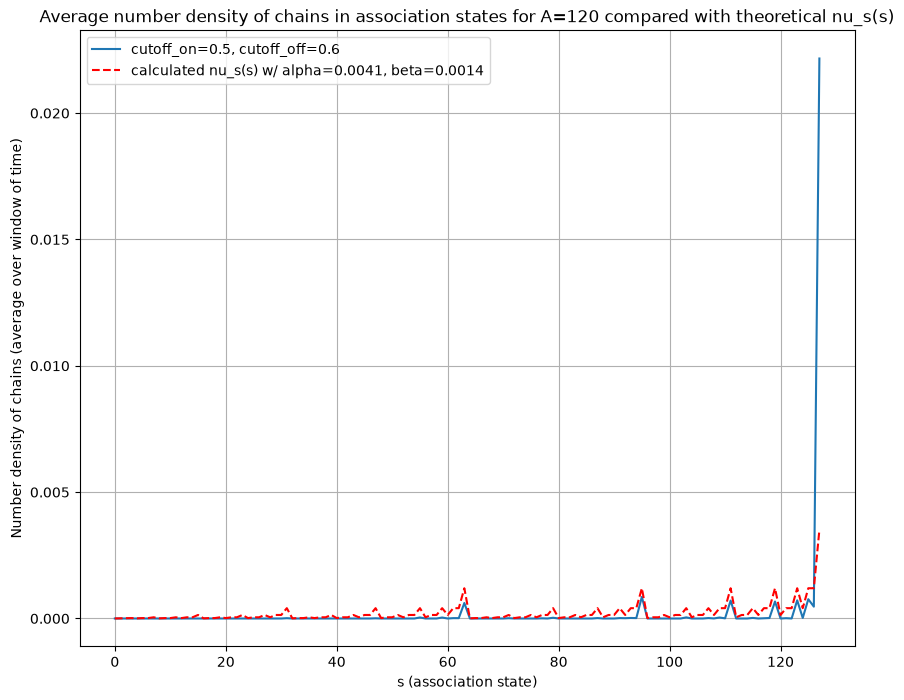

66    238.65201
Name: tau_2, dtype: float64
chi squared for 0.5 0.7 is 0.2862823143824436


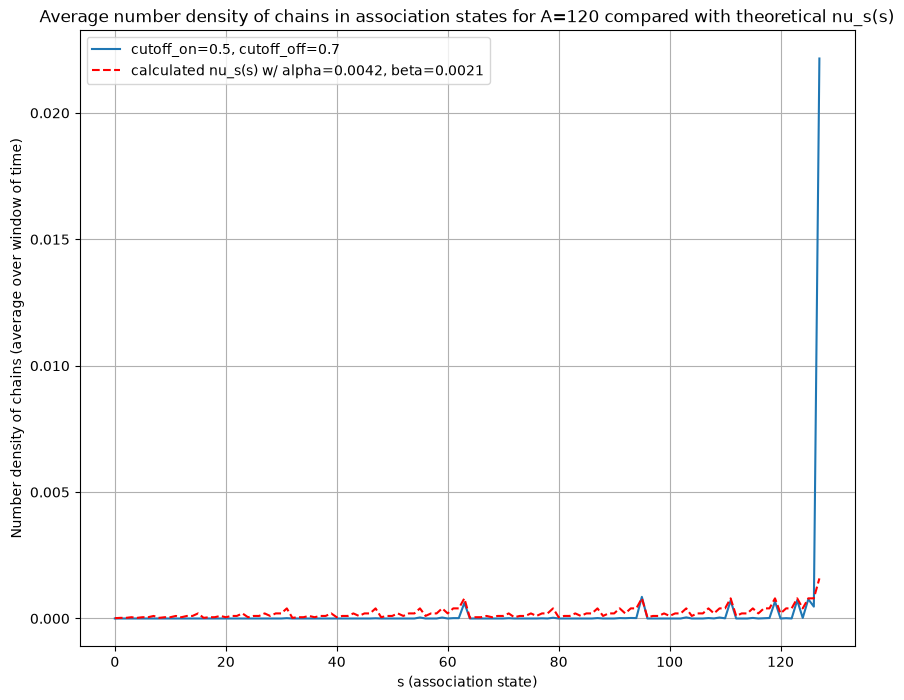

67    149.13347
Name: tau_2, dtype: float64
chi squared for 0.6 0.6 is 0.043374210974465435


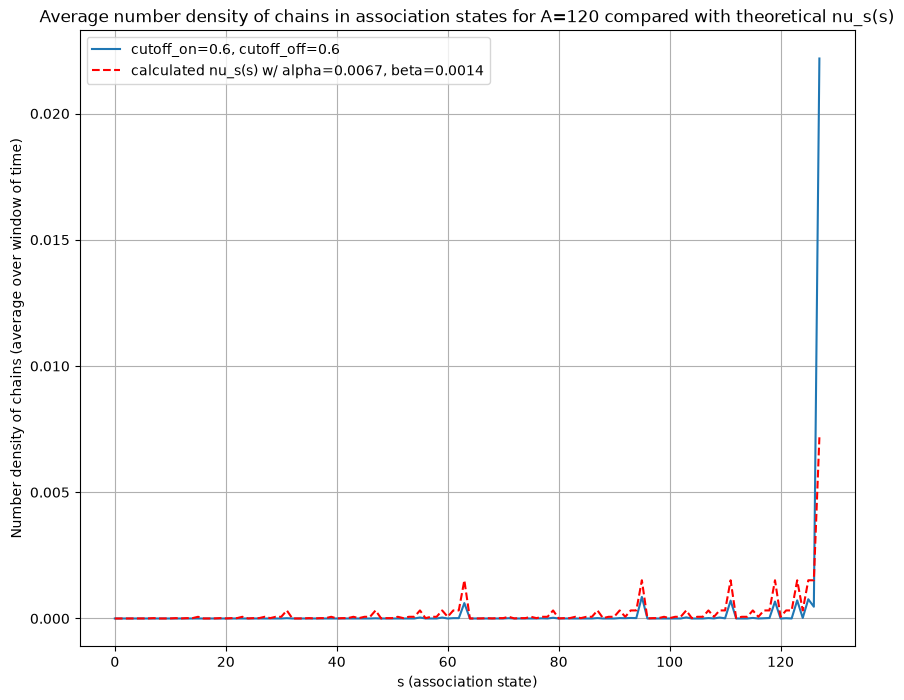

68    171.659129
Name: tau_2, dtype: float64
chi squared for 0.6 0.7 is 0.13085045265025944


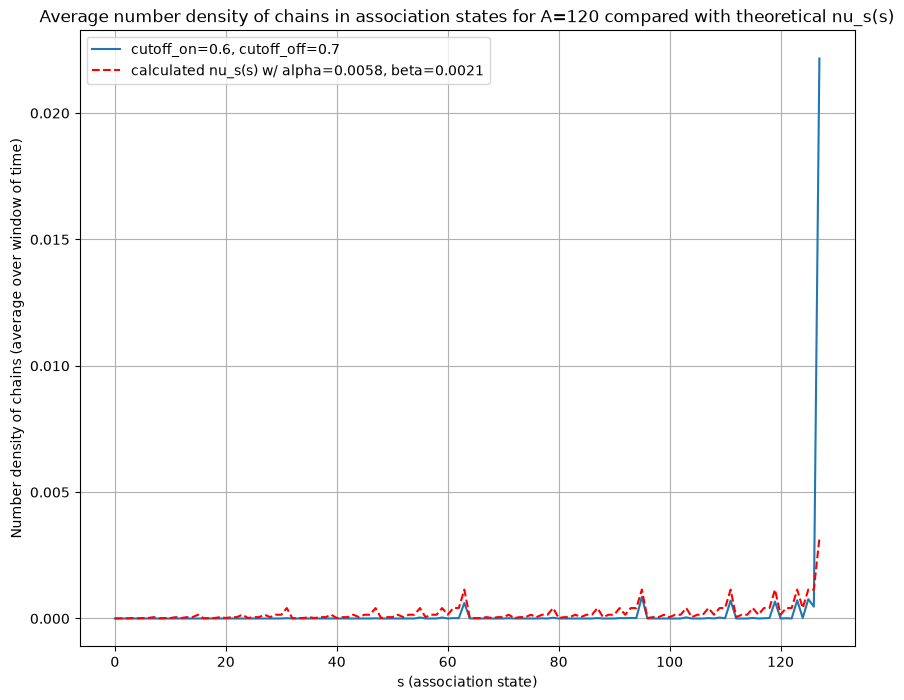

69    32.563961
Name: tau_2, dtype: float64
chi squared for 0.7 0.7 is 0.0041926701059105545


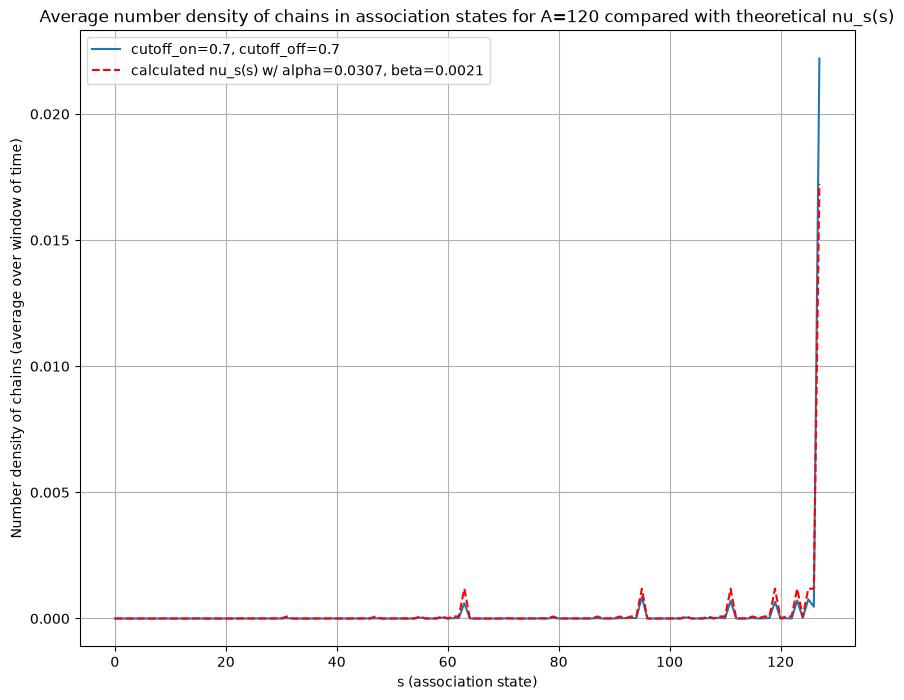

Lowest chi squared value: 0.0041926701059105545 for cutoff_on=0.7, cutoff_off=0.7
70    504.814384
Name: tau_2, dtype: float64
chi squared for 0.4 0.4 is 9287154178287828.0


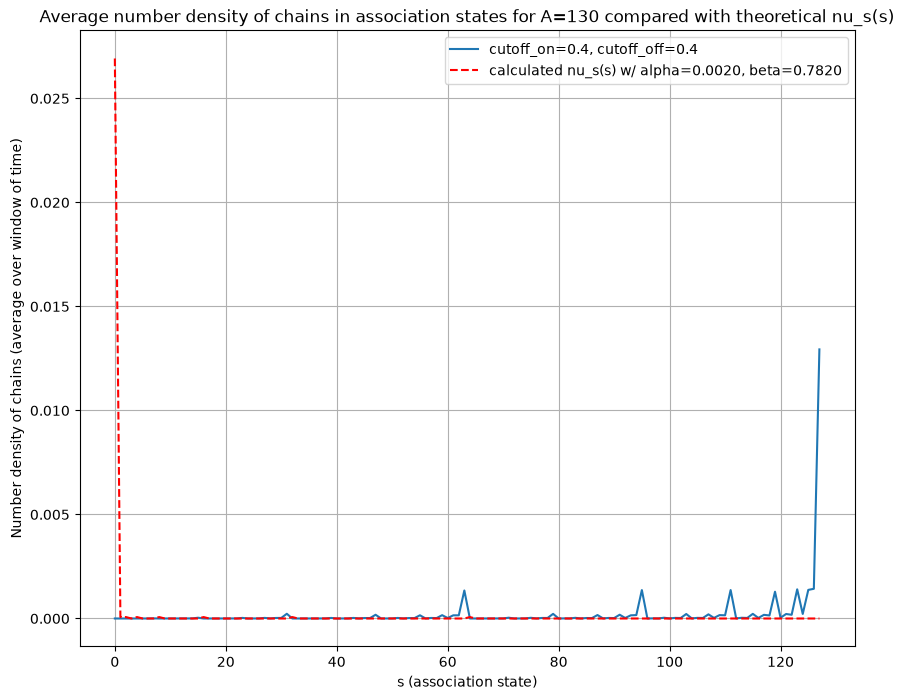

71    504.683906
Name: tau_2, dtype: float64
chi squared for 0.4 0.5 is 18.684394575086262


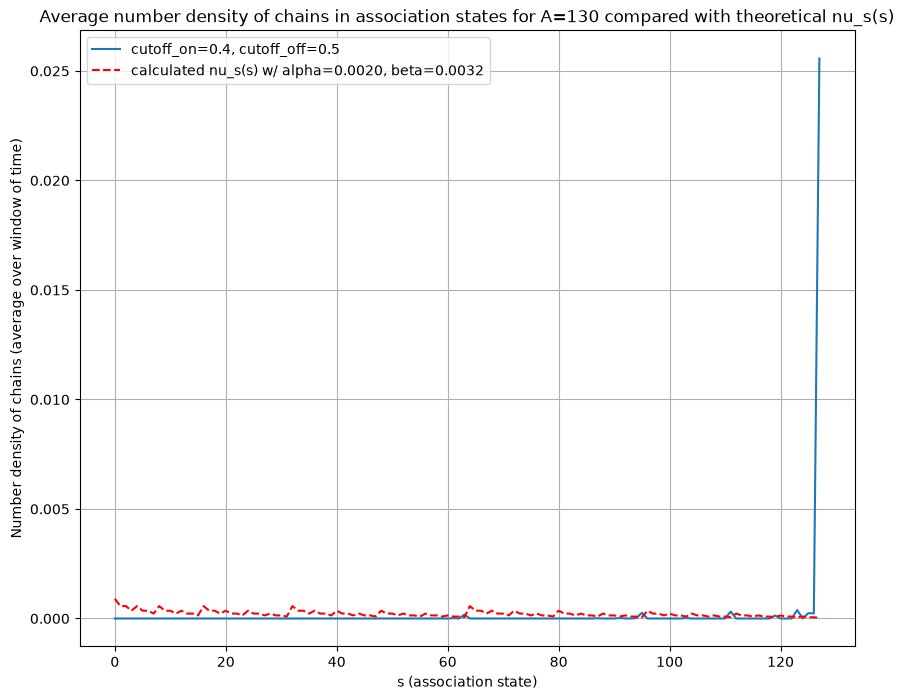

72    504.79691
Name: tau_2, dtype: float64
chi squared for 0.4 0.6 is 0.5232501860390602


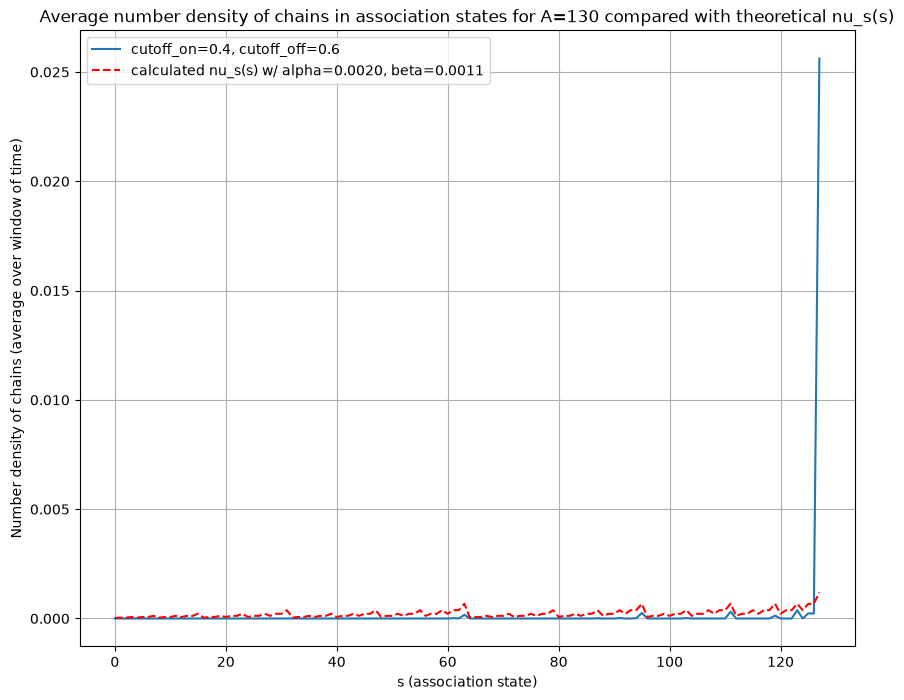

73    503.999811
Name: tau_2, dtype: float64
chi squared for 0.4 0.7 is 0.5010762651199722


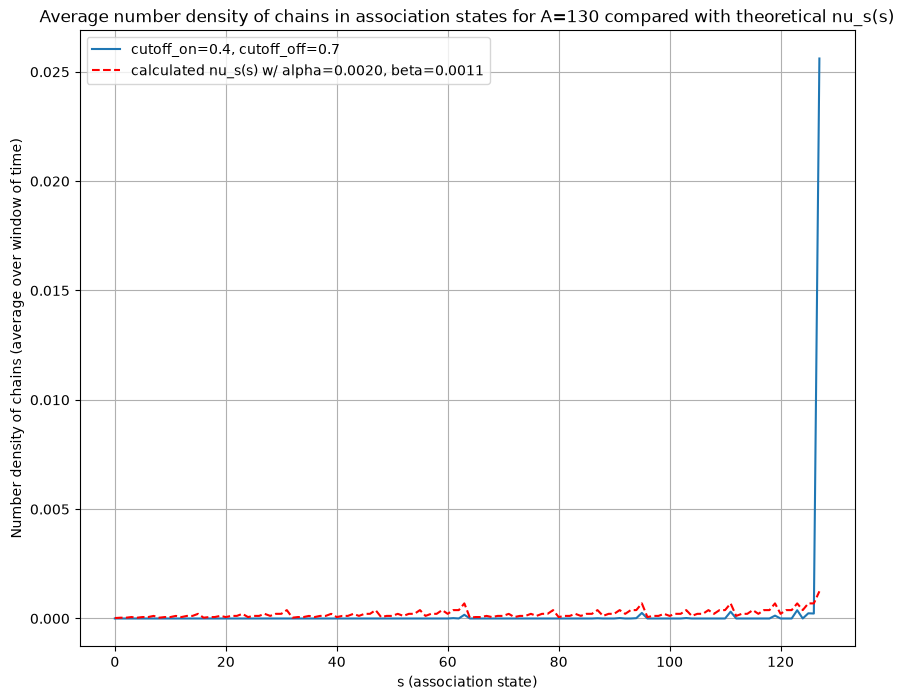

74    81.982031
Name: tau_2, dtype: float64
chi squared for 0.5 0.5 is 0.0925701134413934


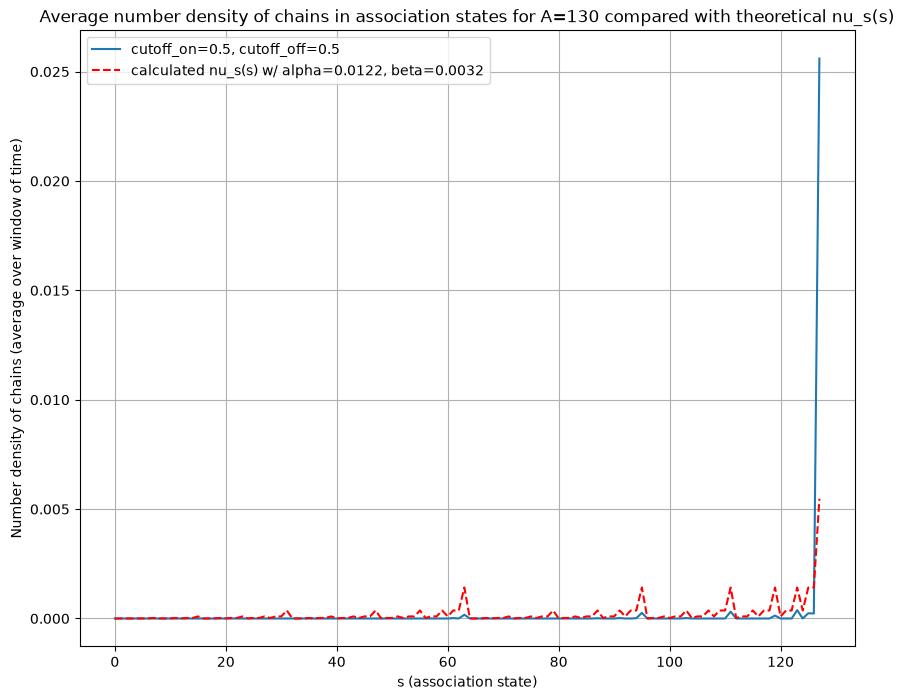

75    81.927022
Name: tau_2, dtype: float64
chi squared for 0.5 0.6 is 0.01717021317770595


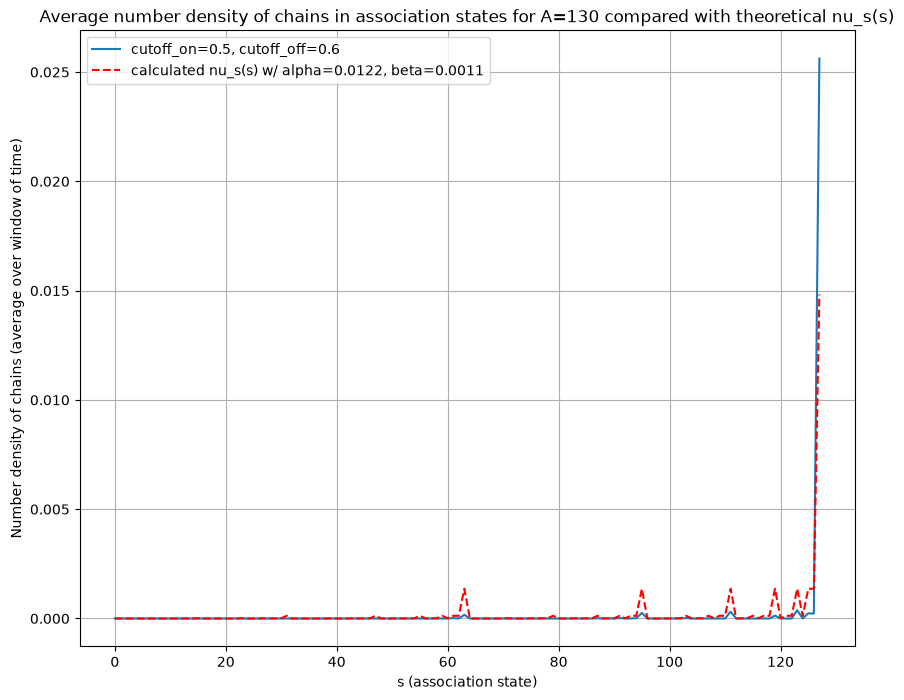

76    81.860623
Name: tau_2, dtype: float64
chi squared for 0.5 0.7 is 0.01675525974629258


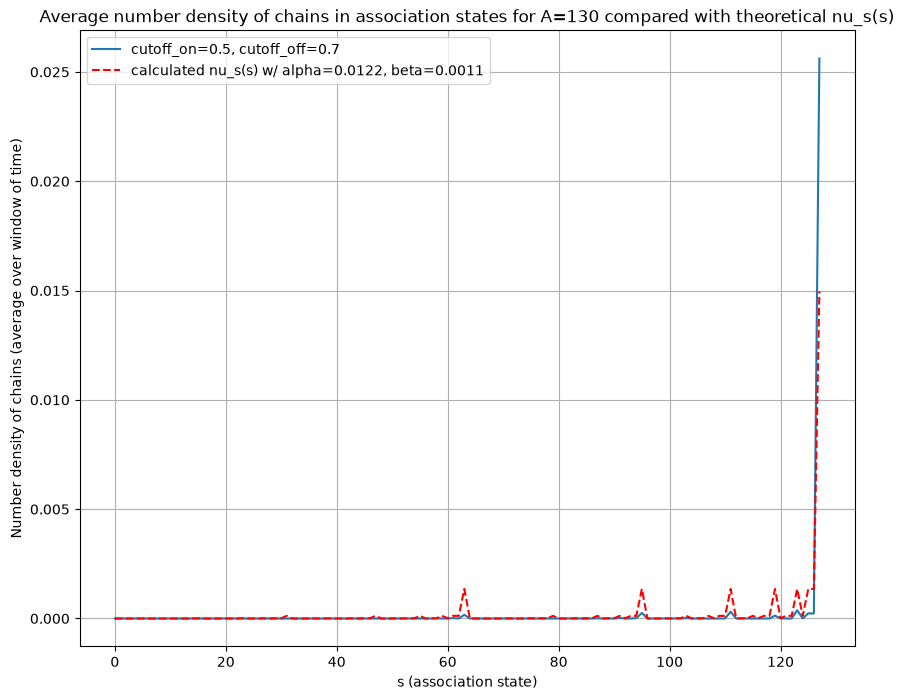

77    94.173529
Name: tau_2, dtype: float64
chi squared for 0.6 0.6 is 0.021212338071390835


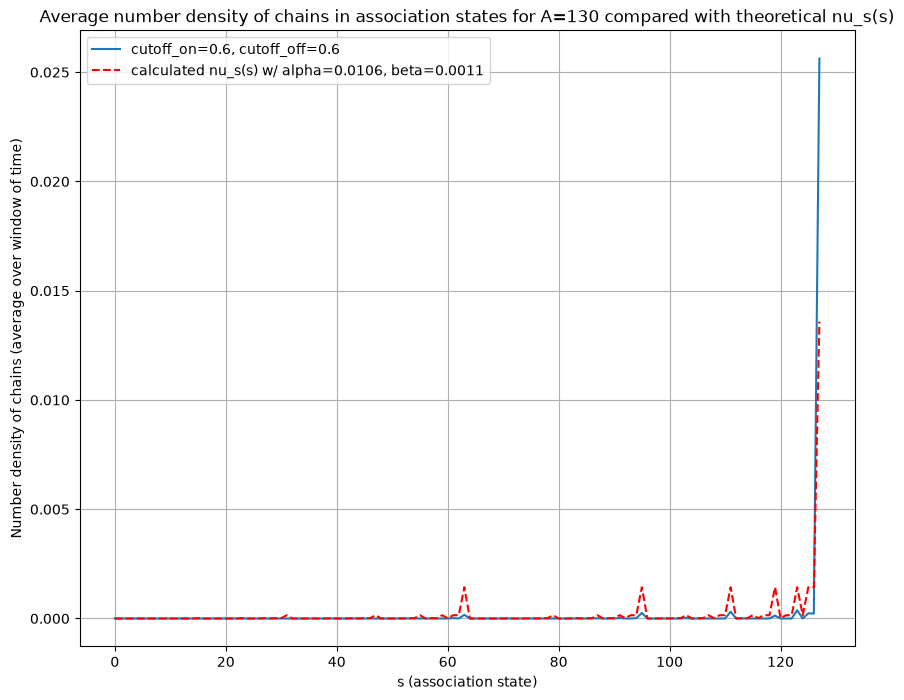

78    94.881431
Name: tau_2, dtype: float64
chi squared for 0.6 0.7 is 0.02094812268619196


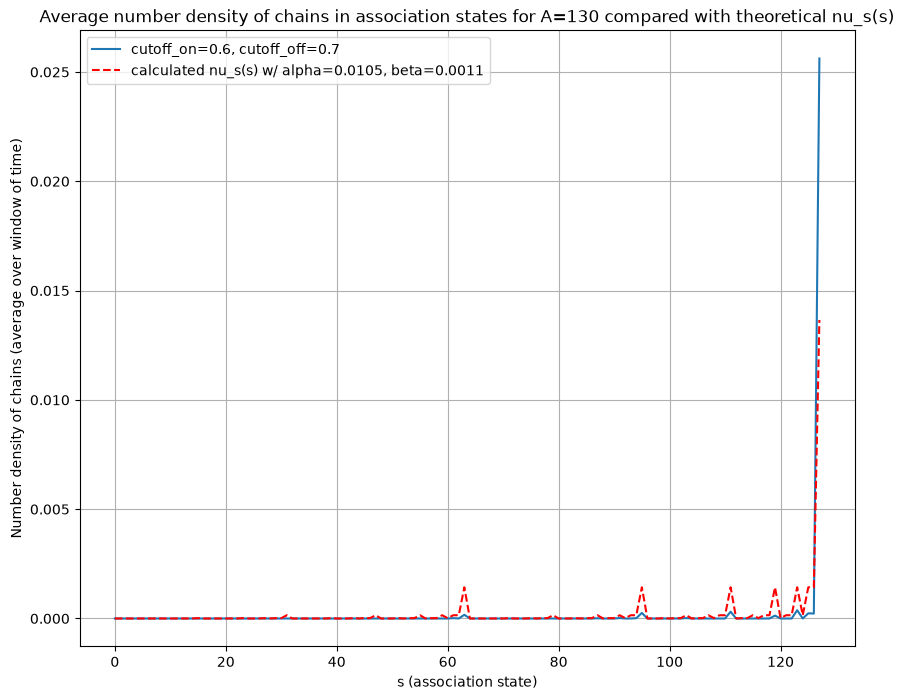

79    74.727389
Name: tau_2, dtype: float64
chi squared for 0.7 0.7 is 0.014659495730240894


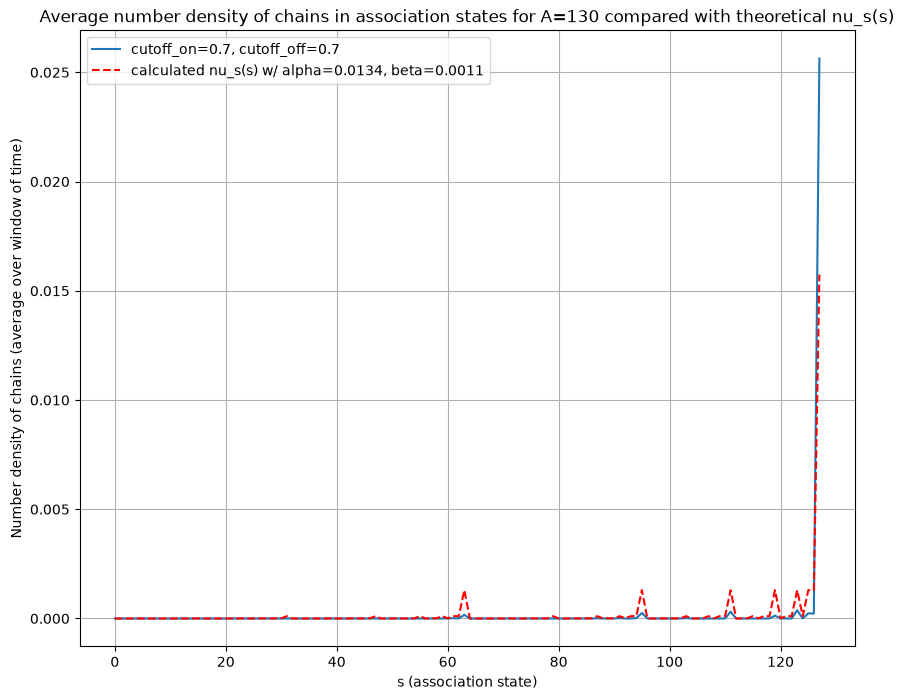

Lowest chi squared value: 0.014659495730240894 for cutoff_on=0.7, cutoff_off=0.7
80    57.810907
Name: tau_2, dtype: float64
chi squared for 0.4 0.4 is 12632328.12517764


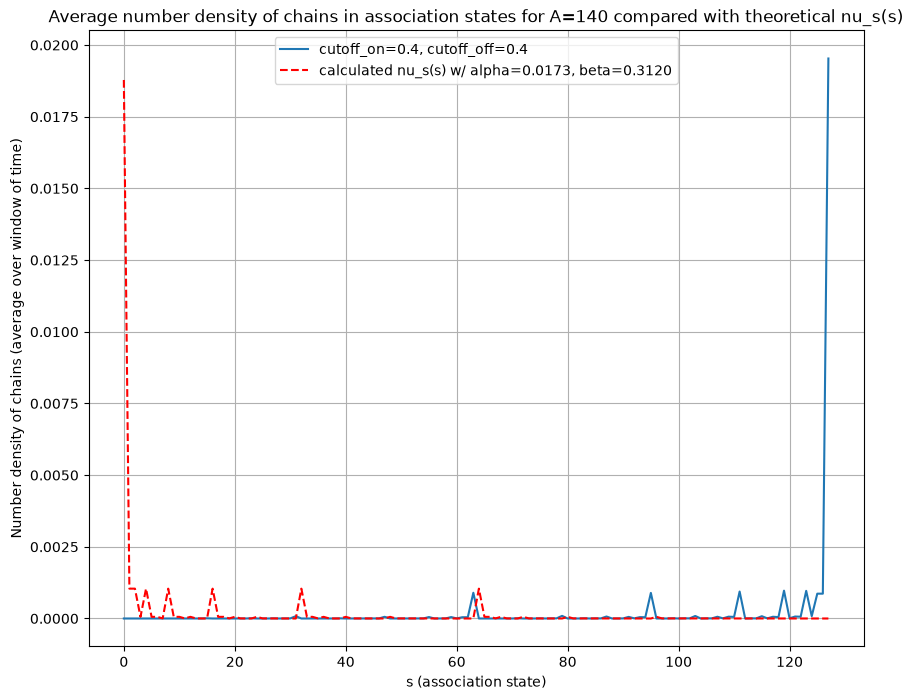

81    57.801272
Name: tau_2, dtype: float64
chi squared for 0.4 0.5 is 0.005903033083072438


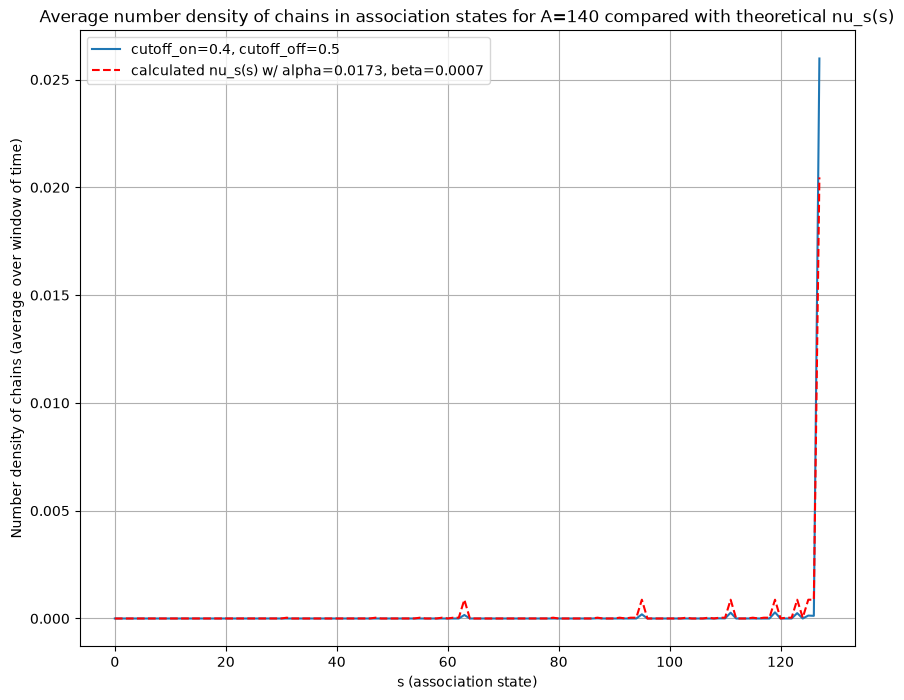

82    53.623116
Name: tau_2, dtype: float64
chi squared for 0.4 0.6 is 0.0010225844063970122


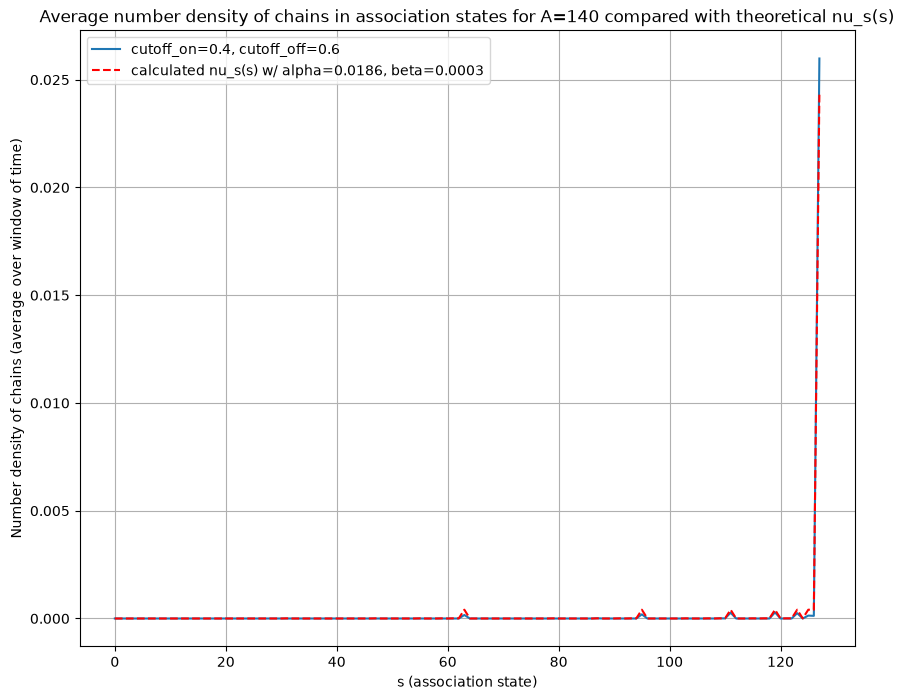

83    49.224732
Name: tau_2, dtype: float64
chi squared for 0.4 0.7 is 0.009344410154897167


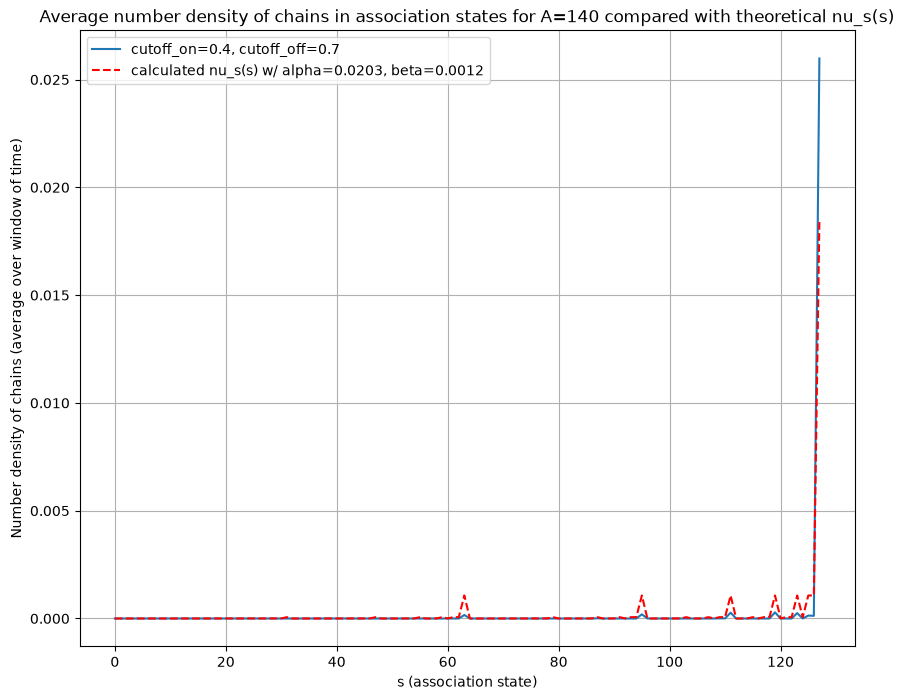

84    66.265666
Name: tau_2, dtype: float64
chi squared for 0.5 0.5 is 0.007315934790545783


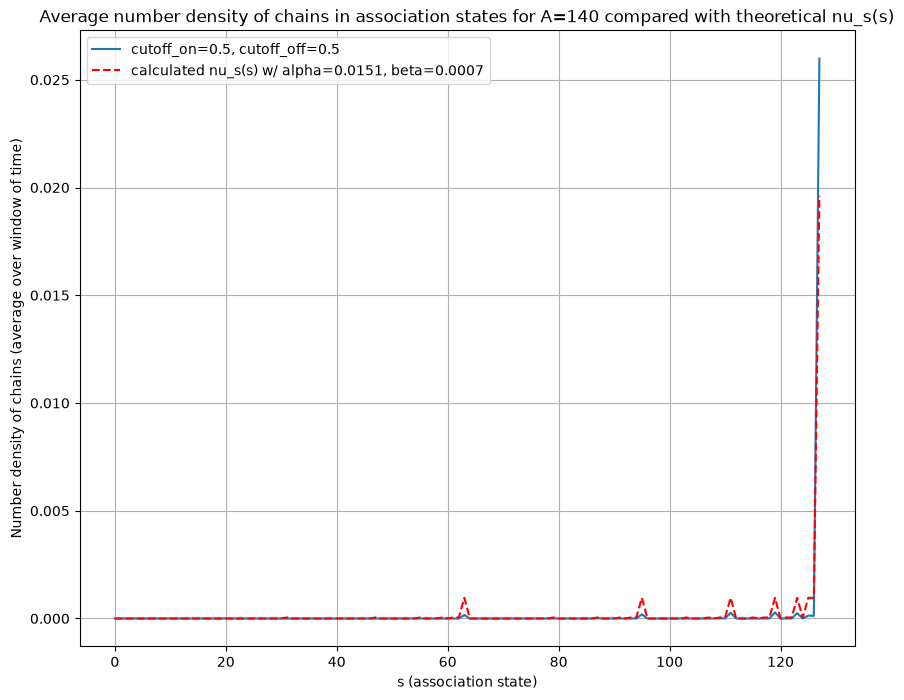

85    66.243696
Name: tau_2, dtype: float64
chi squared for 0.5 0.6 is 0.0016485656997499397


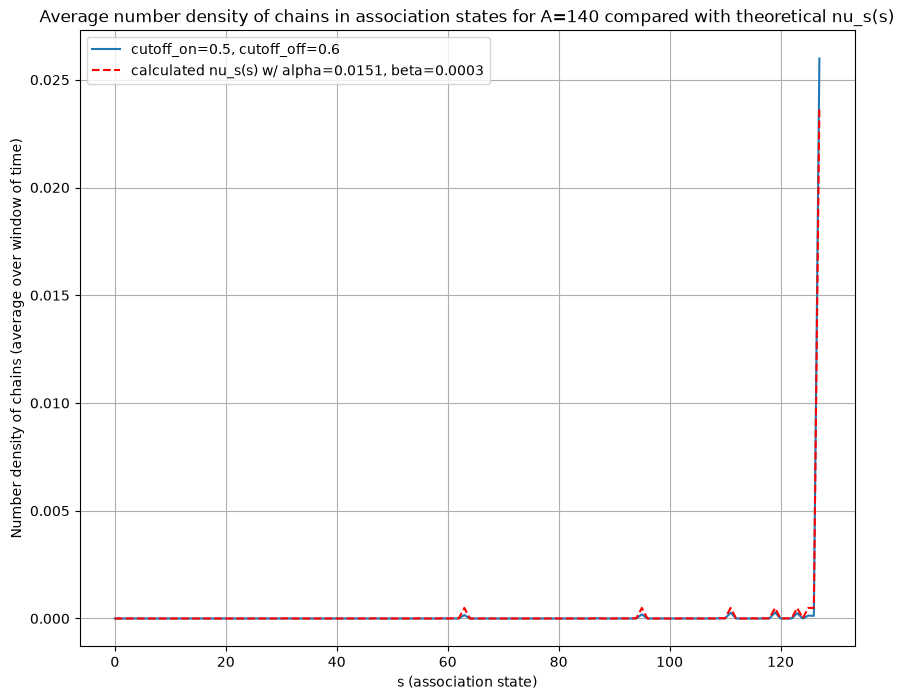

86    66.210731
Name: tau_2, dtype: float64
chi squared for 0.5 0.7 is 0.014403276923562688


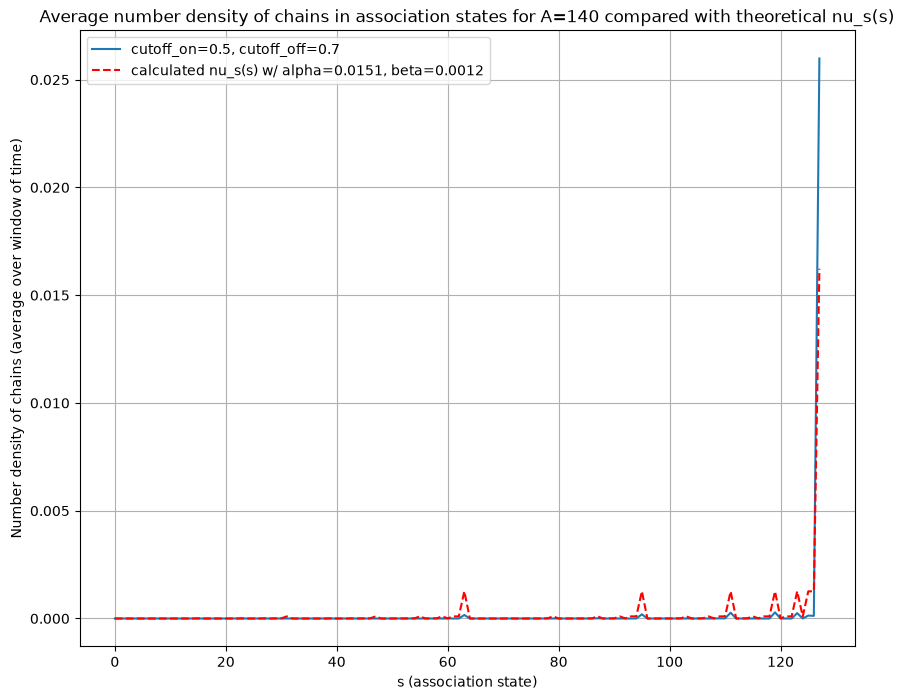

87    74.809876
Name: tau_2, dtype: float64
chi squared for 0.6 0.6 is 0.0021180596620390068


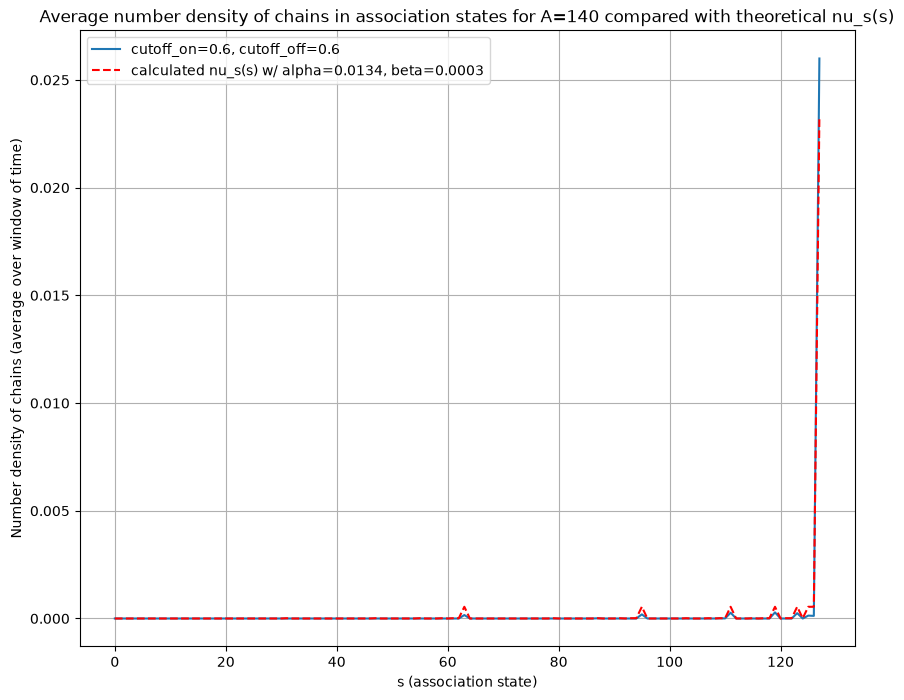

88    71.004061
Name: tau_2, dtype: float64
chi squared for 0.6 0.7 is 0.01594714692105998


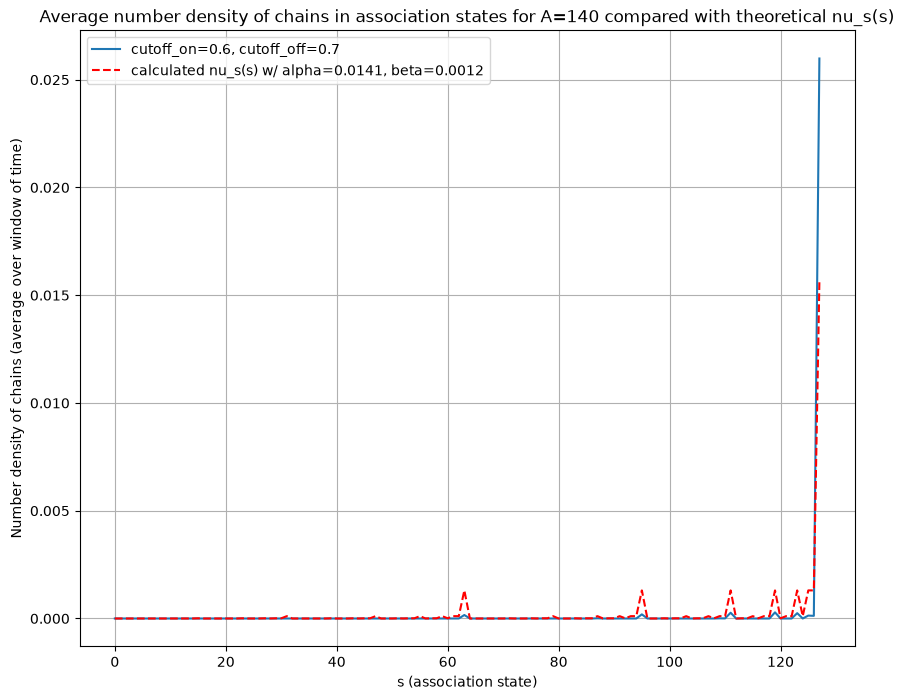

89    48.406225
Name: tau_2, dtype: float64
chi squared for 0.7 0.7 is 0.009167987983281415


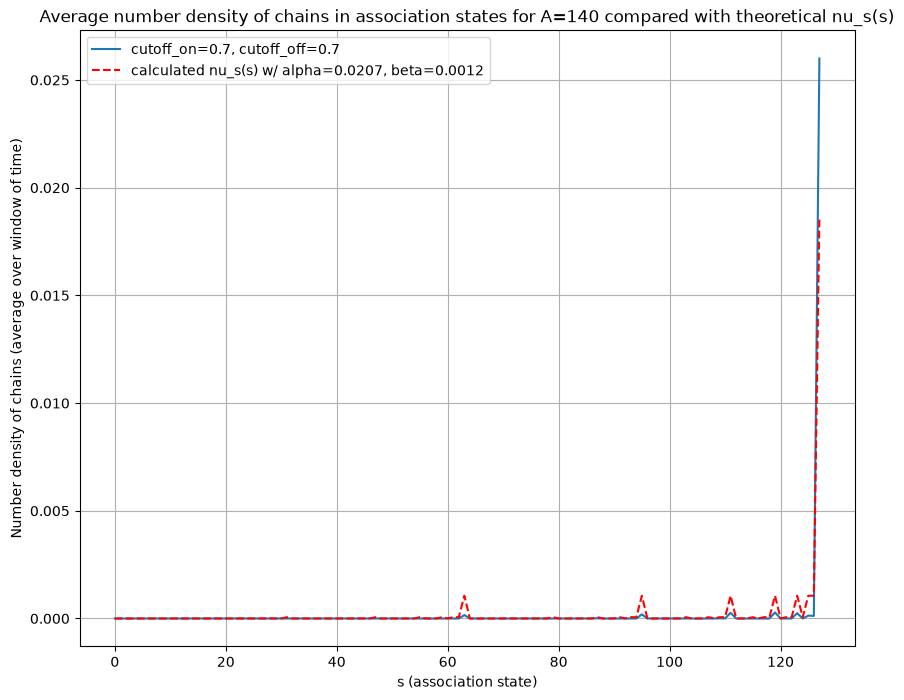

Lowest chi squared value: 0.0010225844063970122 for cutoff_on=0.4, cutoff_off=0.6
90    145.338124
Name: tau_2, dtype: float64
chi squared for 0.4 0.4 is 25086411.44706478


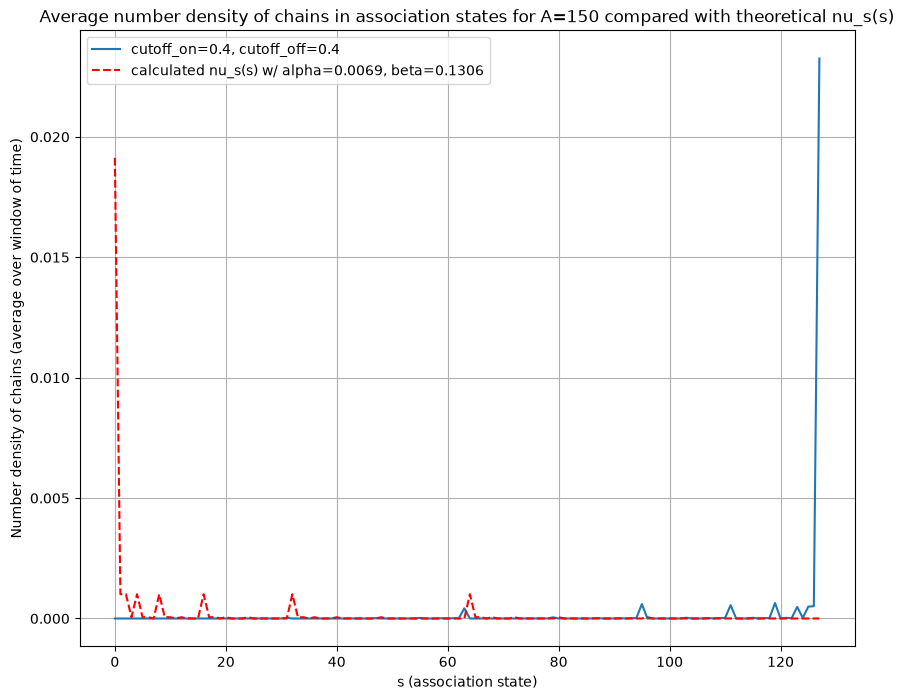

91    145.336858
Name: tau_2, dtype: float64
chi squared for 0.4 0.5 is 0.03060609808252638


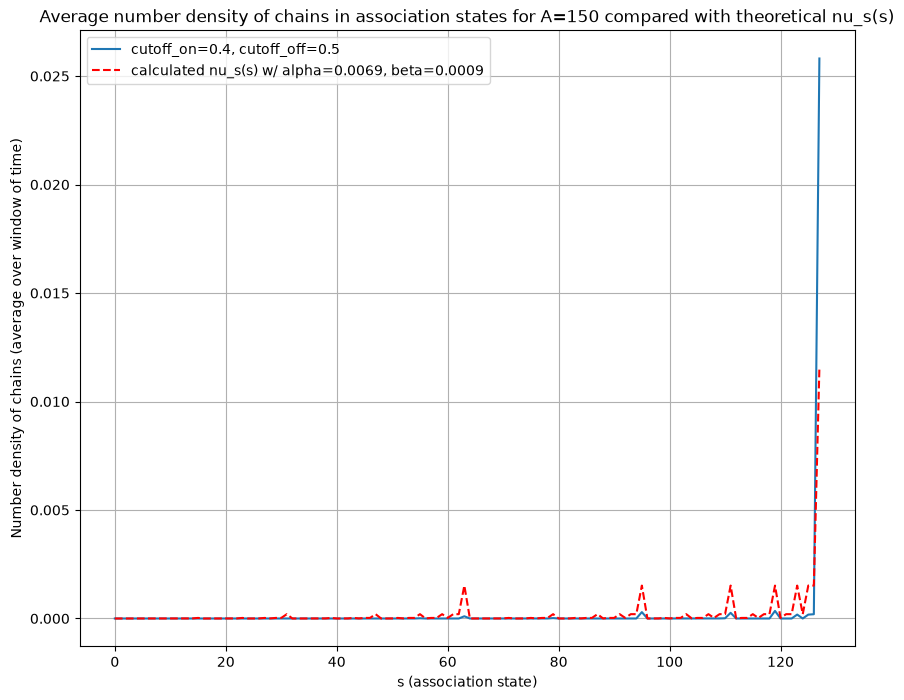

92    163.820872
Name: tau_2, dtype: float64
chi squared for 0.4 0.6 is 0.05711172046258694


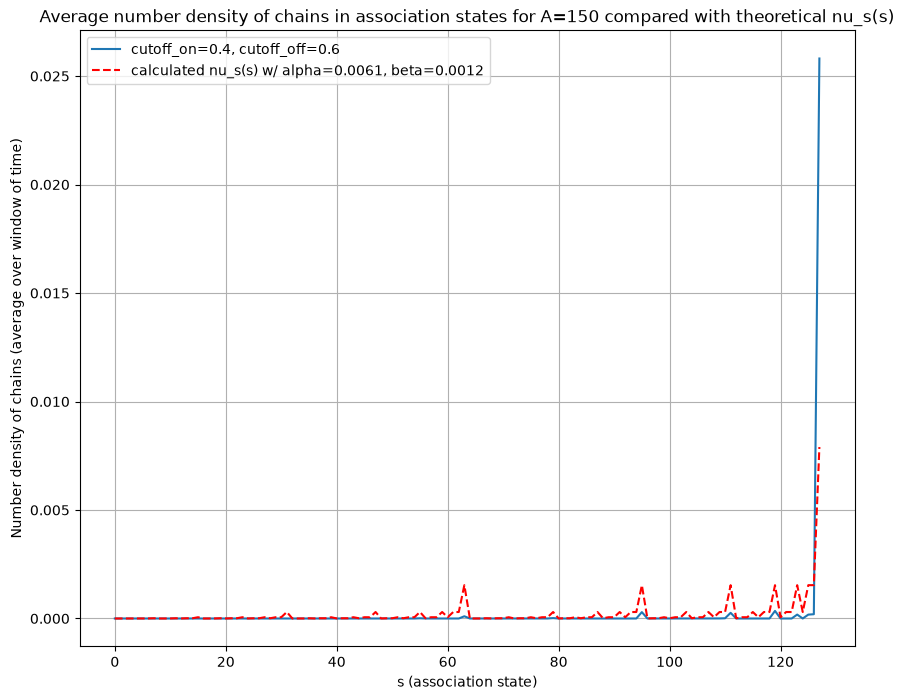

93    163.701573
Name: tau_2, dtype: float64
chi squared for 0.4 0.7 is 0.11308332623199277


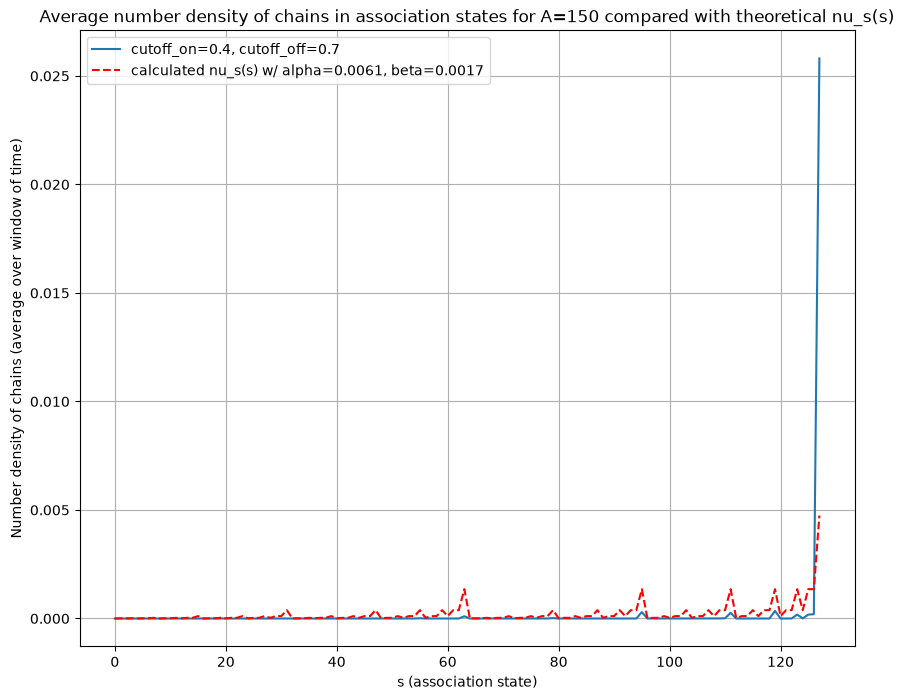

94    183.468752
Name: tau_2, dtype: float64
chi squared for 0.5 0.5 is 0.044186982061376376


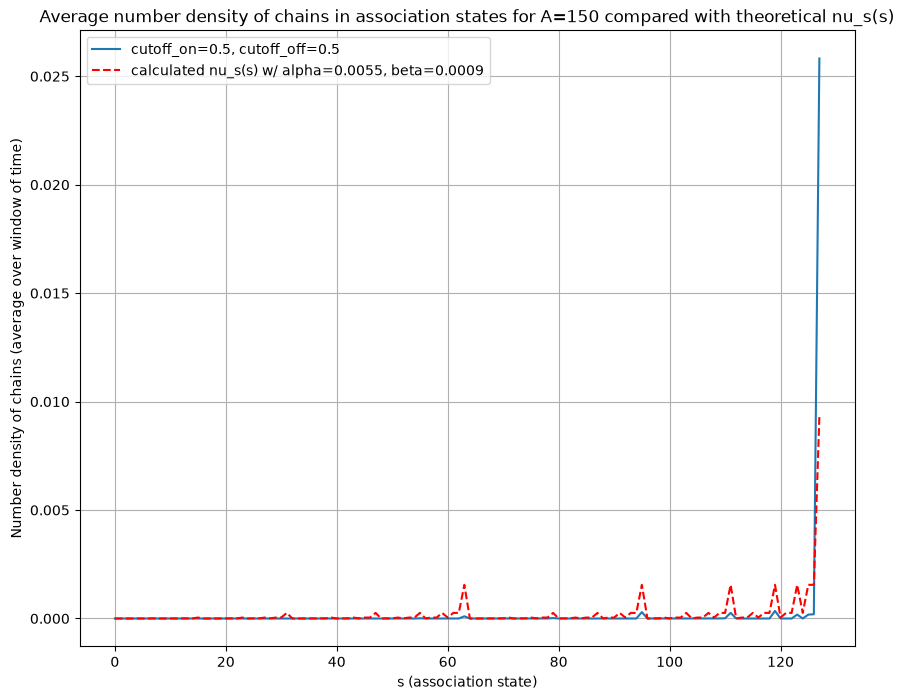

95    197.697208
Name: tau_2, dtype: float64
chi squared for 0.5 0.6 is 0.07914750787232812


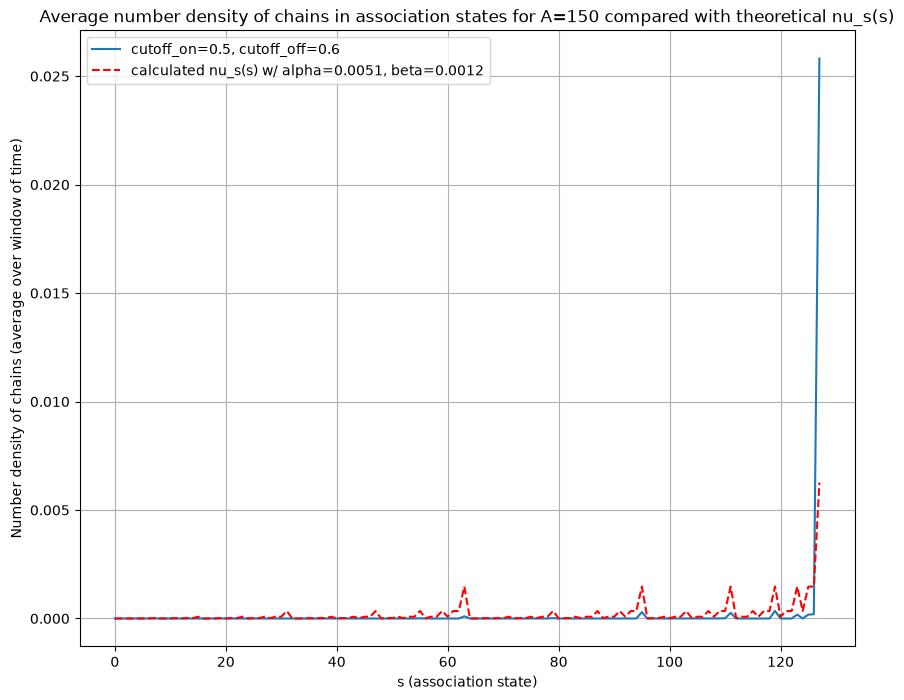

96    194.42188
Name: tau_2, dtype: float64
chi squared for 0.5 0.7 is 0.15946890517321963


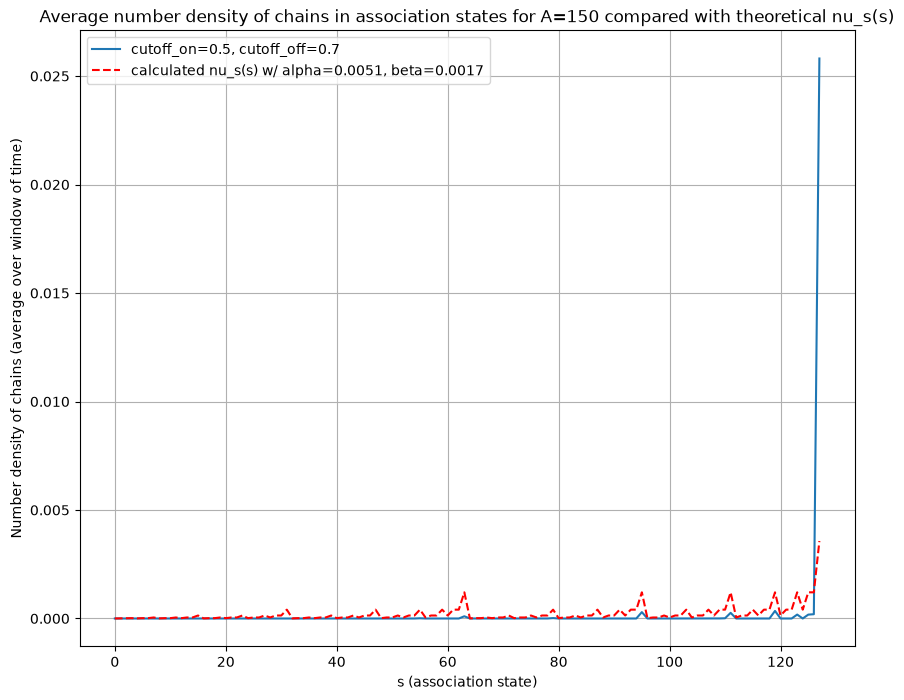

97    70.50656
Name: tau_2, dtype: float64
chi squared for 0.6 0.6 is 0.015572020882607058


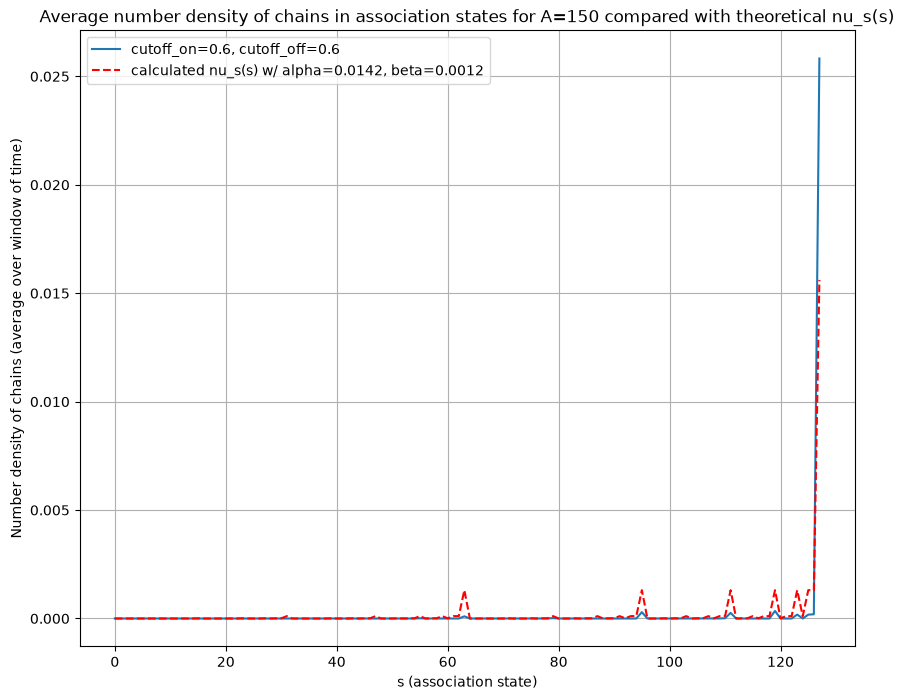

98    69.28282
Name: tau_2, dtype: float64
chi squared for 0.6 0.7 is 0.026729410196097578


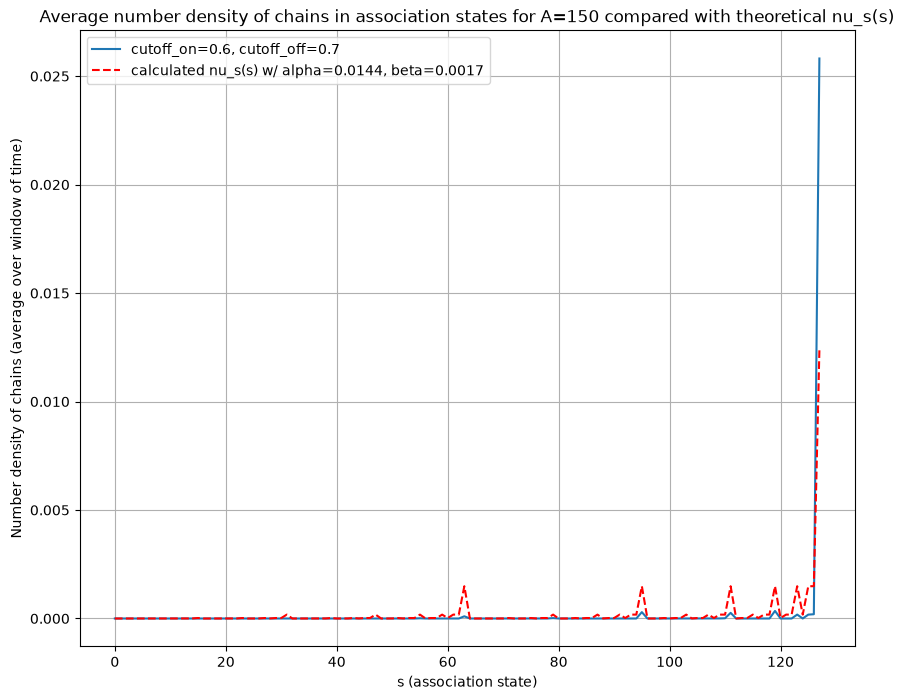

99    76.616376
Name: tau_2, dtype: float64
chi squared for 0.7 0.7 is 0.031233269396399296


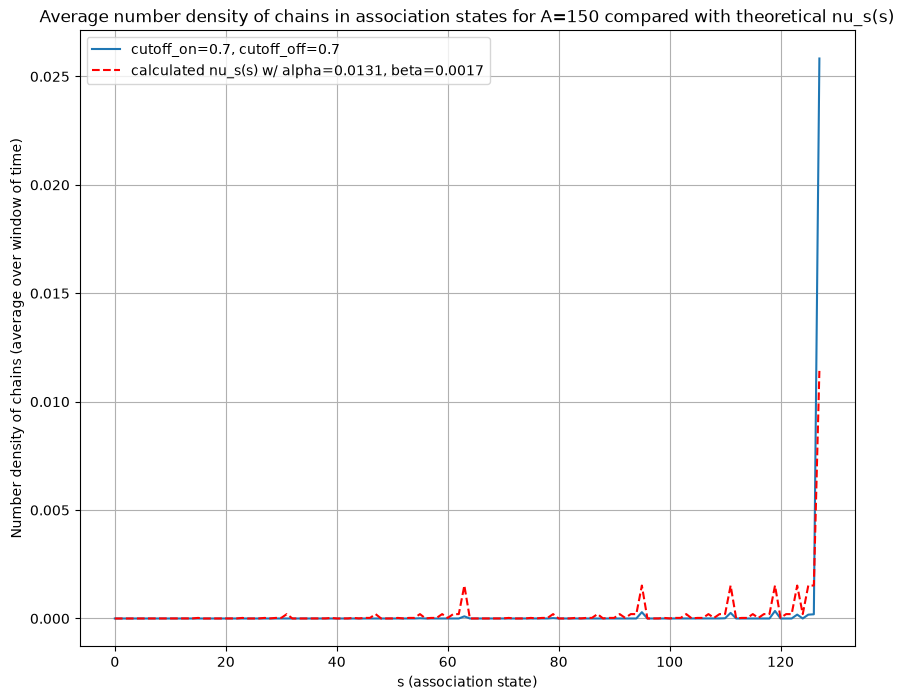

Lowest chi squared value: 0.015572020882607058 for cutoff_on=0.6, cutoff_off=0.6


In [39]:
for A in As:
    fit_nu_s_spectrum(A)